# Reload config

In [1]:
import sys
for m in [k for k in sys.modules if k == "RCP_analysis" or k.startswith("RCP_analysis.")]:
    del sys.modules[m]

import RCP_analysis.python.functions.config_loading as cfg
print(cfg.PARAMS.location, cfg.PARAMS.session)
print(cfg.OUT_BASE)

 
/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/results


In [2]:
# Units are tracked (sorted on the concatenated recording), so the same unit_id
# is the same neuron in every condition. Spike trains are read straight out of the
# stitched Cal files, where positions are already indices within Intan_idx.
 
from pathlib import Path
 
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
 
import RCP_analysis as rcp
from RCP_analysis.python.functions.config_loading import *  # PARAMS, OUT_BASE, roots
 
%matplotlib inline
 
FS_INTAN = 30000.0
FS_VEL = 1000.0
VEL_THRESH = 85.0  # deg/s, matches MATLAB +/-85 crossing rule
 
WIN_PRE_S = 0.8
WIN_POST_S = 1.2
WIN_MS = (-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
 
NPRW_RATES = PARAMS.NPRW_rate_est
BIN_MS = 30
STEP_MS = 10
SIGMA_MS = 30
NORMALIZE_FIRST_MS = 150.0
 
# Stim blanking params
STIM_MS_BEFORE = float(NPRW_RATES.get("remove_ms_before", 20.0))
STIM_TAIL_MS = float(NPRW_RATES.get("remove_tail_ms_after", 20.0))
STIM_DUR_MS = 100.0  # stim train duration; blank runs -STIM_MS_BEFORE to STIM_DUR_MS + STIM_TAIL_MS
 
DATA_ROOT = Path(str(PARAMS.data_root))
SESSION_DIR = DATA_ROOT / "Bert/BL_RW_003_Session_1"
CAL_ROOT = SESSION_DIR / "Calibrated"
 
OUT_FIG_DIR = OUT_BASE / "figures" / "per_unit_cross_condition"
OUT_FIG_DIR.mkdir(parents=True, exist_ok=True)


# Conditions

In [3]:
# "stitch" picks which stitched copy to read. Keep every condition on
# _stitched_all_sess: unit ids are only comparable within a single sort.
 
ALL_SESS = "_stitched_all_sess"
 
CONDITIONS = [
    {
        "label": "Passive HoB",
        "kind": "baseline",
        "cal": CAL_ROOT / "IntanFile_1" / "BL_closed_loop_STIM_003_003_Cal.mat",
        "stitch": ALL_SESS,
        "peak_times_passive_ipsi": [17.579, 20.974, 24.119, 27.526, 31.043, 34.266, 37.244, 40.461, 43.869, 47.226],
        "peak_times_passive_contra": [16.2, 19.434, 22.518, 26.027, 29.263, 32.425, 35.59, 38.885, 41.978, 45.523, 49.915],
    },
    {
        "label": "Active HoB (Early)",
        "kind": "baseline",
        "cal": CAL_ROOT / "IntanFile_1" / "BL_closed_loop_STIM_003_004_Cal.mat",
        "stitch": ALL_SESS,
        "peak_times_active_ipsi": [14.146, 17.795, 21.477, 25.424, 29.449, 33.545, 37.44, 41.59],
        "peak_times_active_contra": [15.911, 19.723, 23.197, 27.366, 31.659, 35.227, 39.445],
    },
    {
        "label": "Active HoB (Mid)",
        "kind": "baseline",
        "cal": CAL_ROOT / "IntanFile_9" / "BL_closed_loop_STIM_003_011_Cal.mat",
        "stitch": ALL_SESS,
    },
    {
        "label": "Active HoB (Late)",
        "kind": "baseline",
        "cal": CAL_ROOT / "IntanFile_14" / "BL_closed_loop_STIM_003_016_Cal.mat",
        "stitch": ALL_SESS,
    },
    {
        "label": "Active stim (BR_008)",
        "kind": "stim",
        "cal": CAL_ROOT / "IntanFile_5" / "BL_closed_loop_STIM_003_008_Cal_stim.mat",
        "stitch": ALL_SESS,
    },
    {
        "label": "Active stim (BR_009)",
        "kind": "stim",
        "cal": CAL_ROOT / "IntanFile_7" / "BL_closed_loop_STIM_003_009_Cal.mat",
        "stitch": ALL_SESS,
    },
    {
        "label": "Active stim (BR_018)",
        "kind": "stim",
        "cal": CAL_ROOT / "IntanFile_16" / "BL_closed_loop_STIM_003_018_Cal_stim.mat",
        "stitch": ALL_SESS,
    },
]

In [4]:
# Helper functions
STIM_PREFIX = "stim_"
 
def stitched_path(cond):
    """
    Path to the stitched copy of a condition's Cal file.
 
    Args:
        cond: a CONDITIONS entry with 'cal' and 'stitch' keys.
    Returns:
        Path to <stem><stitch>.mat next to the original.
    """
    cal = cond["cal"]
    return cal.with_name(cal.stem + cond["stitch"] + cal.suffix)

def _seg_col1(seg, name):
    """
    Column 1 of a segments field, in seconds. Returns None if absent.

    h5py transposes MATLAB arrays, so a MATLAB (n,2) reads as (2,n) and column 1
    is row 0. Values are ms, matching the active_like_stim_* convention.
    """
    if name not in seg:
        return None
    arr = np.asarray(seg[name], float)
    col1 = arr[0, :] if arr.ndim == 2 else arr.ravel()
    return np.sort(col1 / 1000.0)

def load_cal_bundle(cal_path):
    """
    Read velocity, per-unit spike times, segmented event times, and stim blocks.

    Unit fields hold positions within Intan_idx, so seconds is just / FS_INTAN --
    no re-alignment needed. Stim block bounds were stitched in as *_pos fields on
    the same basis, so they convert the same way; -1 marks a block outside this
    Cal file's span. Reading via h5py so we don't pull the whole file into RAM.
    Note h5py returns MATLAB arrays transposed, so a MATLAB (n,2) is (2,n) here.

    Args:
        cal_path: path to a stitched v7.3 Cal .mat with a 'Data' group.
    Returns:
        vel, spikes {unit_id: times_s}, pos_times, neg_times (ms; None if no
        segments), stim_onsets_s (None if the file has no stitched stim blocks),
        catch_events (per-direction catch trial times in seconds from the
        catch_pos/catch_neg segments fields; None per direction when absent).
    """
    with h5py.File(str(cal_path), "r") as f:
        data = f["Data"]
        vel = np.asarray(data["headYawVel"], float).ravel()
        spikes = {
            int(k.split("unit_")[1]): np.asarray(data[k]).ravel().astype(np.int64) / FS_INTAN
            for k in data.keys() if k.startswith("unit_")
        }
        if "segments" in data:
            seg = data["segments"]
            pos = np.asarray(seg["active_like_stim_pos"], float)
            neg = np.asarray(seg["active_like_stim_neg"], float)
            # row 0 = MATLAB column 1 = peak times (ms); guard the single-peak case
            pos_times = pos[0, :] if pos.ndim == 2 else pos.ravel()
            neg_times = neg[0, :] if neg.ndim == 2 else neg.ravel()
            catch_events = {"ipsi": _seg_col1(seg, "catch_pos"),
                            "contra": _seg_col1(seg, "catch_neg")}
        else:
            pos_times = neg_times = None
            catch_events = {"ipsi": None, "contra": None}

        key = f"{STIM_PREFIX}block_bounds_samples_pos"
        if key in data:
            bb = np.asarray(data[key], np.int64)
            if bb.ndim == 2 and bb.shape[0] == 2:
                bb = bb.T  # undo the h5py/MATLAB transpose -> (n_blocks, 2)
            in_span = np.all(bb >= 0, axis=1) if bb.ndim == 2 else (bb >= 0)
            onsets = bb[in_span, 0] if bb.ndim == 2 else bb[in_span]
            stim_onsets_s = np.sort(np.asarray(onsets, float) / FS_INTAN)
        else:
            stim_onsets_s = None

    return vel, spikes, pos_times, neg_times, stim_onsets_s, catch_events
 
def match_events_to_stim(events_s, stim_onsets_s, tol_ms=150.0):
    """
    Tag each event with the nearest stim block onset.

    Events come from the velocity segmentation; onsets come from the Intan stim
    stream. An event with no onset within tol_ms had no stim delivered.

    Args:
        events_s: event times in seconds.
        stim_onsets_s: stim block onsets in seconds, sorted.
        tol_ms: match tolerance.
    Returns:
        (matched mask, signed lag in ms; +ve means the event follows the onset).
    """
    events_s = np.asarray(events_s, float)
    if events_s.size == 0:
        return np.zeros(0, bool), np.zeros(0)
    if stim_onsets_s is None or stim_onsets_s.size == 0:
        return np.zeros(events_s.size, bool), np.full(events_s.size, np.nan)

    j = np.clip(np.searchsorted(stim_onsets_s, events_s), 1, stim_onsets_s.size - 1)
    left, right = stim_onsets_s[j - 1], stim_onsets_s[j]
    nearest = np.where(np.abs(events_s - left) <= np.abs(right - events_s), left, right)
    lag_ms = (events_s - nearest) * 1000.0
    return np.abs(lag_ms) <= tol_ms, lag_ms
 
def detect_vel_crossings(vel, annot_times_s, direction,
                         search_pre_s=0.4, search_post_s=0.4, thresh=VEL_THRESH):
    """
    Find the true yaw-velocity threshold crossing near each manual annotation.
 
    For each annotation time, searches [annot-pre, annot+post] for the first
    crossing of +/-thresh (upward through +thresh for 'pos'/ipsi, downward through
    -thresh for 'neg'/contra), matching the MATLAB pos_cross/neg_cross rule.
 
    Args:
        vel: yaw velocity trace (deg/s) at FS_VEL.
        annot_times_s: manual reach annotation times in seconds.
        direction: 'pos' (ipsi, +thresh) or 'neg' (contra, -thresh).
        search_pre_s: window start before each annotation, in seconds.
        search_post_s: window end after each annotation, in seconds.
        thresh: velocity threshold in deg/s.
    Returns:
        Detected crossing times in seconds, sorted and de-duplicated.
    """
    vel = np.asarray(vel, float)
    if direction == "pos":
        cross_idx = np.where((vel[:-1] < thresh) & (vel[1:] >= thresh))[0] + 1
    else:
        cross_idx = np.where((vel[:-1] > -thresh) & (vel[1:] <= -thresh))[0] + 1
    cross_t = cross_idx / FS_VEL
 
    detected = []
    for a in annot_times_s:
        in_win = cross_t[(cross_t >= a - search_pre_s) & (cross_t <= a + search_post_s)]
        if in_win.size:
            detected.append(in_win[0])  # first crossing in the window
    return np.unique(np.array(detected))
 
 
def get_gaussian_rates(spikes_s, events_s, ms_before, tail_ms):
    """
    Compute per-trial firing rates via the RCP edge-aware Gaussian path.
 
    Args:
        spikes_s: one unit's spike times in seconds (condition-relative).
        events_s: event times in seconds (stim onset or velocity crossing).
        ms_before: blank window before each event, in ms (0 for baseline).
        tail_ms: blank window after each event, in ms (0 for baseline).
    Returns:
        rates_hz [n_trials, n_bins], rel_t_s (bin-center time axis in seconds).
    """
    if events_s.size == 0:
        return np.zeros((0, 0)), np.zeros(0)
    peaks_ms = {0: spikes_s * 1000.0}  # single-key dict: unit flows through rcp as one channel
 
    counts, rel_ms, widths, left_bins = rcp.bin_counts_around_stim(
        peaks_ms, BIN_MS, events_s * 1000.0, ms_before, tail_ms, WIN_MS, step_ms=STEP_MS,
    )
    rates = rcp.smooth_counts_gauss(counts, widths, rel_ms, SIGMA_MS, left_bins)
 
    # RCP pipeline uses channels; drop the single-channel axis -> trials x time
    return rates[:, 0, :], rel_ms / 1000.0
 
 
def blank_params(kind):
    """Blank window for a condition kind: none for baseline, -20 to stim_dur+20 for stim."""
    return (0.0, 0.0) if kind == "baseline" else (STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS)

In [5]:
# Load every condition once, splitting stim conditions into delivered vs catch
#
# A "stim" CONDITIONS entry is a source file, not a plottable condition. Its
# events are matched against the stitched stim block onsets; matched events
# become "<label> [stim]" and events with no block nearby are dropped as
# segmentation errors. Catch trials come from the MATLAB catch_pos/catch_neg
# fields, not from the leftovers, and become "<label> [catch]" with
# kind="baseline" since no stim was delivered and there is nothing to blank.

STIM_MATCH_TOL_MS = 150.0
SUFFIX_STIM, SUFFIX_CATCH = " [stim]", " [catch]"

def _load_one(cond):
    """Read a CONDITIONS entry and derive its events. Returns a cond_cache dict."""
    path = stitched_path(cond)
    vel, spikes, pos_times, neg_times, stim_onsets_s, catch_events = load_cal_bundle(path)

    if cond["kind"] == "baseline":
        ipsi_annot = cond.get("peak_times_passive_ipsi") or cond.get("peak_times_active_ipsi") or []
        contra_annot = cond.get("peak_times_passive_contra") or cond.get("peak_times_active_contra") or []
        if ipsi_annot or contra_annot:
            ipsi = detect_vel_crossings(vel, np.asarray(ipsi_annot, float), "pos")
            contra = detect_vel_crossings(vel, np.asarray(contra_annot, float), "neg")
            src = f"crossings {contra.size}/{len(contra_annot)} contra, {ipsi.size}/{len(ipsi_annot)} ipsi"
        else:
            contra, ipsi = neg_times / 1000.0, pos_times / 1000.0
            src = f"segments {contra.size} contra, {ipsi.size} ipsi"
    else:
        contra, ipsi = neg_times / 1000.0, pos_times / 1000.0
        src = f"segments {contra.size} contra, {ipsi.size} ipsi"

    return dict(vel=vel, t_vel=np.arange(vel.size) / FS_VEL, spikes=spikes,
                kind=cond["kind"], events={"contra": contra, "ipsi": ipsi},
                stim_onsets_s=stim_onsets_s, catch_events=catch_events,
                path=path, src=src)


cond_cache = {}
PLOT_CONDITIONS = []  # what's actually plottable, after splitting

for cond in CONDITIONS:
    base = _load_one(cond)
    n_spk = sum(v.size for v in base["spikes"].values())
    print(f"{cond['label']}: {len(base['spikes'])} units, {n_spk} spikes, "
          f"{base['src']}  [{base['path'].name}]")

    onsets = base["stim_onsets_s"]
    if cond["kind"] != "stim" or onsets is None or onsets.size == 0:
        if cond["kind"] == "stim":
            print("    WARNING: stim condition with no stim blocks in span - not split")
        cond_cache[cond["label"]] = base
        PLOT_CONDITIONS.append(cond)
        continue

    print(f"    {onsets.size} stim blocks in span")
    stim_ev, n_dropped = {}, 0
    for dk in ("contra", "ipsi"):
        ev = base["events"][dk]
        matched, lag = match_events_to_stim(ev, onsets, STIM_MATCH_TOL_MS)
        stim_ev[dk] = ev[matched]
        n_dropped += int((~matched).sum())
        med = np.median(lag[matched]) if matched.any() else np.nan
        iqr = (np.percentile(lag[matched], 75) - np.percentile(lag[matched], 25)
               if matched.sum() > 1 else np.nan)
        print(f"    {dk:6s} {int(matched.sum()):3d} stim, {int((~matched).sum()):3d} dropped, "
              f"lag median {med:7.1f} ms, IQR {iqr:6.1f}")

    # Catch trials come from the segmentation, not from unmatched leftovers
    catch_ev = {dk: (base["catch_events"][dk] if base["catch_events"][dk] is not None
                     else np.zeros(0)) for dk in ("contra", "ipsi")}
    print(f"    catch (labeled): contra {catch_ev['contra'].size}, ipsi {catch_ev['ipsi'].size}")
    if n_dropped:
        print(f"    dropped {n_dropped} events with no matching stim block")

    for events, suffix, kind in ((stim_ev, SUFFIX_STIM, "stim"),
                                 (catch_ev, SUFFIX_CATCH, "baseline")):
        if sum(e.size for e in events.values()) == 0:
            print(f"    no events - {cond['label'] + suffix} not created")
            continue
        new_label = cond["label"] + suffix
        cond_cache[new_label] = {**base, "kind": kind, "events": events}
        PLOT_CONDITIONS.append({**cond, "label": new_label, "kind": kind})

available_units = sorted(cond_cache[CONDITIONS[0]["label"]]["spikes"].keys())
print(f"\n{len(available_units)} units")
print("plottable conditions:", [c["label"] for c in PLOT_CONDITIONS])

Passive HoB: 194 units, 203593 spikes, crossings 11/11 contra, 10/10 ipsi  [BL_closed_loop_STIM_003_003_Cal_stitched_all_sess.mat]
Active HoB (Early): 196 units, 370824 spikes, crossings 7/7 contra, 8/8 ipsi  [BL_closed_loop_STIM_003_004_Cal_stitched_all_sess.mat]
Active HoB (Mid): 161 units, 137323 spikes, segments 14 contra, 13 ipsi  [BL_closed_loop_STIM_003_011_Cal_stitched_all_sess.mat]
Active HoB (Late): 153 units, 120207 spikes, segments 10 contra, 12 ipsi  [BL_closed_loop_STIM_003_016_Cal_stitched_all_sess.mat]
Active stim (BR_008): 181 units, 785027 spikes, segments 55 contra, 34 ipsi  [BL_closed_loop_STIM_003_008_Cal_stim_stitched_all_sess.mat]
    242 stim blocks in span
    contra  55 stim,   0 dropped, lag median   -20.0 ms, IQR   20.3
    ipsi    34 stim,   0 dropped, lag median    -2.1 ms, IQR   15.4
    catch (labeled): contra 0, ipsi 0
    no events - Active stim (BR_008) [catch] not created
Active stim (BR_009): 185 units, 1131188 spikes, segments 83 contra, 62 ipsi  [

# Plot session and labels

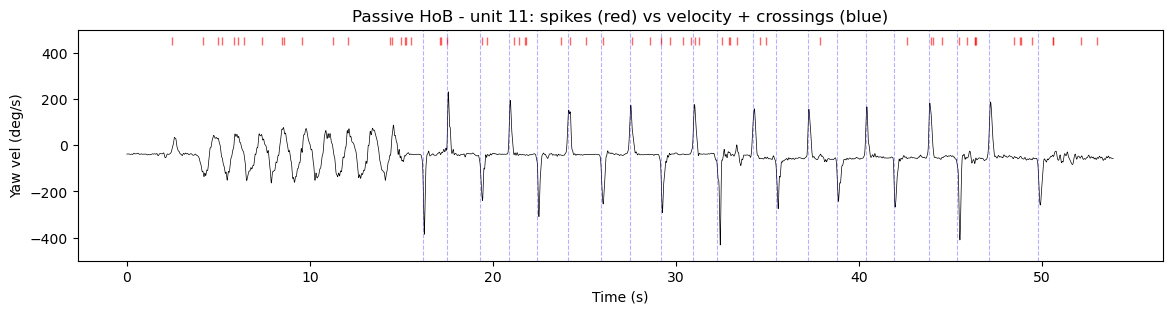

unit 11: 64 spikes, recording 53.9s


In [6]:
# Sanity check: do stitched spikes line up with kinematics in the same file?

test_cond = CONDITIONS[0]
test_uid = 11  # a unit known to be movement-modulated

cc = cond_cache[test_cond["label"]]
spk_s = cc["spikes"][test_uid]

fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(cc["t_vel"], cc["vel"], color="k", lw=0.5)
ax.set_ylim(-500, 500)
ax.plot(spk_s, np.full(spk_s.size, 450), "|", color="r", markersize=6, alpha=0.6)
for p in np.concatenate([cc["events"]["contra"], cc["events"]["ipsi"]]):
    ax.axvline(p, color="b", ls="--", alpha=0.3, lw=0.8)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Yaw vel (deg/s)")
ax.set_title(f"{test_cond['label']} - unit {test_uid}: spikes (red) vs velocity + crossings (blue)")
plt.show()

print(f"unit {test_uid}: {spk_s.size} spikes, recording {cc['t_vel'][-1]:.1f}s")

In [ ]:
from tqdm.auto import tqdm
# Per-unit figure builder
# Rows: 0 peristim kinematics (mean + 95% CI), 1 raster (capped), 2 FR heatmap (all trials), 3 mean PSTH.
# Columns: [direction x condition], direction-major.
# Y-axes and heatmap color scale locked per row across ALL columns.
# Blanked stim bins render as gaps (NaN), not as a compressed axis.
def pick_conds(*labels):
    """
    Select plottable conditions in the order the labels are given.

    Stim source files are split at load into "[stim]" (matched to a stim block)
    and "[catch]" (from the MATLAB catch_pos/catch_neg fields); events matching
    neither are dropped. A bare stim label resolves to its "[stim]" half.
    """
    by_label = {c["label"]: c for c in PLOT_CONDITIONS}
    out = []
    for l in labels:
        if l in by_label:
            out.append(by_label[l])
        elif l + SUFFIX_STIM in by_label:
            out.append(by_label[l + SUFFIX_STIM])  # bare stim label -> delivered half
        else:
            raise KeyError(f"no such condition: {l!r}. Available: {list(by_label)}")
    return out

def get_aligned_vel(t_vel, vel, events, pre_s, post_s, dt_s=None):
    """
    Interpolate the velocity trace onto a common event-aligned time grid.

    Args:
        t_vel, vel: velocity trace timestamps (s) and values.
        events: event times (s) to align to.
        pre_s, post_s: window before/after each event (s).
        dt_s: grid step (s); defaults to the median sample interval.
    Returns:
        (rel_s, segs) with segs shape (n_trials, n_samples), all-NaN trials dropped.
    """
    if t_vel.size < 2 or vel.size == 0 or events.size == 0:
        return np.zeros(0), np.zeros((0, 0))
    if dt_s is None:
        dt_s = float(np.median(np.diff(t_vel)))
    rel_s = np.arange(-pre_s, post_s + dt_s, dt_s)
    segs = np.full((events.size, rel_s.size), np.nan)
    for i, t0 in enumerate(events):
        tq = t0 + rel_s
        ok = (tq >= t_vel[0]) & (tq <= t_vel[-1])  # never extrapolate past the trace
        segs[i, ok] = np.interp(tq[ok], t_vel, vel)
    return rel_s, segs[~np.all(np.isnan(segs), axis=1)]


def mean_ci(segs, z=1.96):
    """
    Across-trial mean and normal-approximation CI, NaN-safe.

    Args:
        segs: (n_trials, n_samples) aligned traces.
        z: CI multiplier on the SEM (1.96 = 95%).
    Returns:
        (mean, lo, hi); empty arrays if segs is empty.
    """
    if segs.size == 0:
        return np.zeros(0), np.zeros(0), np.zeros(0)
    n = np.sum(~np.isnan(segs), axis=0)
    mean = np.where(n > 0, np.nanmean(np.where(n > 0, segs, 0.0), axis=0), np.nan)
    sd = np.nanstd(segs, axis=0, ddof=1) if segs.shape[0] > 1 else np.zeros(mean.shape)
    half = z * sd / np.sqrt(np.maximum(n, 1))
    half = np.where(n < 2, np.nan, half)
    return mean, mean - half, mean + half

def insert_blank_gap(rel_ms, mat):
    """
    Insert a NaN column wherever bins are non-contiguous (a real blanked window).

    Centers jump by BIN_MS at t=0 in every condition because bins never straddle
    the event; that jump still covers every sample. Only a jump larger than
    BIN_MS means data was actually removed.

    Args:
        rel_ms: bin centers (ms), ascending.
        mat: (n_rows, n_bins) values aligned to rel_ms.
    Returns:
        (rel_ms_out, mat_out), unchanged when there is no true blank.
    """
    gaps = np.where(np.diff(rel_ms) > BIN_MS + 1e-9)[0]
    if gaps.size == 0:
        return rel_ms, mat
    fill_ms = [(rel_ms[i] + rel_ms[i + 1]) / 2.0 for i in gaps]
    return np.insert(rel_ms, gaps + 1, fill_ms), np.insert(mat, gaps + 1, np.nan, axis=1)


def build_columns(plot_conds):
    """
    Build the column spec and raster trial cap for a set of conditions.

    Args:
        plot_conds: list of CONDITIONS entries to compare, left to right.
    Returns:
        (columns, n_cap_raster) where columns is one dict per (direction, condition).
    """
    n_contra = min(cond_cache[c["label"]]["events"]["contra"].size for c in plot_conds)
    n_ipsi = min(cond_cache[c["label"]]["events"]["ipsi"].size for c in plot_conds)
    print(f"trial cap: contra n={n_contra}, ipsi n={n_ipsi}")

    directions = [("Contra", "contra", n_contra, "b"), ("Ipsi", "ipsi", n_ipsi, "g")]
    columns = [
        dict(dir_label=dir_label, dir_key=dir_key, n_cap=n_cap, color=color, cond=cond)
        for dir_label, dir_key, n_cap, color in directions
        for cond in plot_conds
    ]
    return columns, max(n_contra, n_ipsi)

# TEMP diagnostic: pull pre-blanking and blanked traces around events
# Rebuilds the same lazy chain the preprocessing notebook blanked, so the two
# can be overlaid. Nothing here is needed for the normal figures.

import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.extractors as se
from probeinterface import Probe
from scipy.io import loadmat

_GEOM_PATH = rcp.resolve_probe_geom_path(PARAMS, REPO_ROOT, session_key=None)
_NPRW_CFG = PARAMS.probes.get("NPRW")
_INTAN_STREAM = _NPRW_CFG.get("neural_data_stream")
_RADII = (_NPRW_CFG.get("local_radius_inner"), _NPRW_CFG.get("local_radius_outer"))
_BLANKED_DIR = OUT_BASE / "checkpoints" / "NPRW_blanked_sessions"

_mat_probe = loadmat(Path(_GEOM_PATH))
_chanmap = _mat_probe["chanMap0ind"].ravel()
_probe = Probe(ndim=2)
_probe.set_contacts(
    positions=np.c_[_mat_probe["xcoords"].ravel(), _mat_probe["ycoords"].ravel()],
    shapes="square", shape_params={"width": 12.0},
)
_probe.set_device_channel_indices(_chanmap)

_sess_folders = rcp.list_intan_sessions(INTAN_ROOT)


def _build_pre_blank(sess_folder):
    """Rebuild bandpass + local CMR lazily, i.e. the input blank_session received."""
    rec = se.read_split_intan_files(sess_folder, mode="concatenate",
                                    stream_name=_INTAN_STREAM, use_names_as_ids=True)
    rec = rec.set_probe(_probe)
    rec = rcp.reorder_recording_to_geometry(rec, _chanmap)
    rec = spre.unsigned_to_signed(rec)
    rec = spre.bandpass_filter(rec, freq_min=float(PARAMS.highpass_hz),
                               freq_max=float(PARAMS.lowpass_hz), dtype="float32")
    return spre.common_reference(rec, reference="local", operator="median",
                                 local_radius=_RADII)


def cond_session_folder(cond):
    """
    Map a CONDITIONS entry to its Intan session folder via the IntanFile_N dir.

    Mirrors CAL_DIR_FOR_SESSION from the stitching notebook: session index i
    (0-based) corresponds to IntanFile_{i+1}.
    """
    intan_dir = cond["cal"].parent.name  # e.g. "IntanFile_9"
    idx = int(intan_dir.split("_")[1]) - 1
    return _sess_folders[idx]


_raw_cache = {}

def get_raw_recs(cond):
    """Load (pre-blanking, blanked, Intan_idx) for a condition, cached."""
    label = cond["label"]
    if label in _raw_cache:
        return _raw_cache[label]
    sess = cond_session_folder(cond)
    rec_pre = _build_pre_blank(sess)
    blank_path = _BLANKED_DIR / sess.name
    rec_post = si.load(blank_path) if blank_path.exists() else None
    with h5py.File(str(stitched_path(cond)), "r") as f:
        intan_idx = np.asarray(f["Data"]["Intan_idx"]).ravel().astype(np.int64)
    print(f"{label}: session {sess.name}, Intan_idx {intan_idx.size} samples, "
          f"blanked {'found' if rec_post is not None else 'MISSING'}")
    _raw_cache[label] = (rec_pre, rec_post, intan_idx)
    return _raw_cache[label]


def get_raw_segs(cond, events_s, pre_s, post_s, channels=None, trials=None,
                 max_trials=5, reduce="rms"):
    """
    Event-aligned raw traces, pre-blanking and blanked.

    Events are in Cal-file time, so each is converted to a recording sample by
    indexing Intan_idx at round(t * FS_INTAN). That lookup is the alignment
    assumption the rest of the notebook relies on.

    Args:
        cond: CONDITIONS entry.
        events_s: event times in Cal-file seconds.
        pre_s, post_s: window around each event.
        channels: channel indices to read; None reads a spread of 16.
        trials: explicit trial indices into events_s. None takes the first
            max_trials. Indices with no readable window are skipped and
            reported in the returned list.
        max_trials: cap when trials is None.
        reduce: "rms" or "max" across channels.
    Returns:
        (rel_ms, pre_segs, post_segs, used) where used holds the trial indices
        actually plotted, aligned with the rows of pre_segs.
    """
    rec_pre, rec_post, intan_idx = get_raw_recs(cond)
    n_ch = rec_pre.get_num_channels()
    if channels is None:
        channels = np.linspace(0, n_ch - 1, 16).astype(int)
    n_tot = rec_pre.get_num_samples()

    idx_list = list(range(min(max_trials, events_s.size))) if trials is None else list(trials)

    pre_n = int(pre_s * FS_INTAN)
    post_n = int(post_s * FS_INTAN)
    rel_ms = (np.arange(-pre_n, post_n) / FS_INTAN) * 1000.0

    pre_rows, post_rows, used, skipped = [], [], [], []
    for ti in idx_list:
        if ti < 0 or ti >= events_s.size:
            skipped.append((ti, "out of range"))
            continue
        pos = int(round(float(events_s[ti]) * FS_INTAN))
        if pos < 0 or pos >= intan_idx.size:
            skipped.append((ti, "outside Intan_idx"))
            continue
        center = int(intan_idx[pos])  # Cal position -> recording sample
        s0, s1 = center - pre_n, center + post_n
        if s0 < 0 or s1 > n_tot:
            skipped.append((ti, "window past recording edge"))
            continue

        def grab(rec):
            tr = rec.get_traces(start_frame=s0, end_frame=s1,
                                channel_ids=rec.channel_ids[channels])
            tr = np.asarray(tr, float)
            return np.sqrt((tr ** 2).mean(axis=1)) if reduce == "rms" \
                else np.abs(tr).max(axis=1)

        pre_rows.append(grab(rec_pre))
        if rec_post is not None:
            post_rows.append(grab(rec_post))
        used.append(ti)

    if skipped:
        print(f"{cond['label']}: skipped trials " +
              ", ".join(f"{t} ({why})" for t, why in skipped))

    pre_segs = np.vstack(pre_rows) if pre_rows else np.zeros((0, rel_ms.size))
    post_segs = np.vstack(post_rows) if post_rows else None
    return rel_ms, pre_segs, post_segs, used

def plot_unit(uid, plot_conds, columns=None, n_cap_raster=None,
              show_raw=False, raw_channels=None, raw_trials=None, raw_max_trials=5):
    """
    Build the 4-row cross-condition figure for one unit.

    Args:
        uid: unit id to plot.
        plot_conds: conditions being compared (for the title).
        columns: output of build_columns.
        n_cap_raster: shared raster row height.
    Returns:
        The matplotlib Figure.
        columns: output of build_columns; rebuilt from plot_conds when None.
        n_cap_raster: shared raster row height; rebuilt with columns when None.
    """
    if columns is None or n_cap_raster is None:
        columns, n_cap_raster = build_columns(plot_conds)
    else:
        want = [c["label"] for c in plot_conds]
        got = list(dict.fromkeys(col["cond"]["label"] for col in columns))
        if want != got:
            raise ValueError(f"columns are stale: built for {got}, plot_conds is {want}")
    n_cols = len(columns)
    n_rows = 5 if show_raw else 4
    heights = [1.5, 2, 1, 1, 1] if show_raw else [2, 1, 1, 1]
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(4 * n_cols, 2 * n_rows), squeeze=False,
        gridspec_kw={"height_ratios": heights},
    )
    r0 = 1 if show_raw else 0  # first non-raw row
    last_im = None

    # Pass 1: compute per-column data and track shared ranges
    col_data = []
    psth_max = vel_absmax = heat_max = raw_max = 0.0
    for col in columns:
        cc = cond_cache[col["cond"]["label"]]
        spk_s = cc["spikes"].get(uid, np.zeros(0))
        events_full = cc["events"][col["dir_key"]]
        events_rast = events_full[:col["n_cap"]]
        msb, tail = blank_params(cc["kind"])

        rates, rel_s = get_gaussian_rates(spk_s, events_full, msb, tail)
        psth = np.nanmean(rates, axis=0) if rates.size else np.zeros(0)
        if psth.size:
            psth_max = max(psth_max, np.nanmax(psth))
        if rates.size:
            heat_max = max(heat_max, np.nanmax(rates))

        rel_vel_s, vel_segs = get_aligned_vel(
            cc["t_vel"], cc["vel"], events_full, WIN_PRE_S, WIN_POST_S
        )
        vel_mean, vel_lo, vel_hi = mean_ci(vel_segs)
        if vel_mean.size:
            finite = np.concatenate([vel_lo, vel_hi])
            finite = finite[np.isfinite(finite)]
            if finite.size:
                vel_absmax = max(vel_absmax, np.nanmax(np.abs(finite)))

        raw = None
        if show_raw:
            raw_rel_ms, raw_pre, raw_post, raw_used = get_raw_segs(
                col["cond"], events_full, WIN_PRE_S, WIN_POST_S,
                channels=raw_channels, trials=raw_trials, max_trials=raw_max_trials,
            )
            raw = dict(rel_ms=raw_rel_ms, pre=raw_pre, post=raw_post, used=raw_used)
            if raw_pre.size:
                raw_max = max(raw_max, float(np.nanmax(raw_pre)))

        col_data.append(dict(col=col, cc=cc, spk_s=spk_s, events_full=events_full,
                             events_rast=events_rast, rel_s=rel_s, rates=rates, psth=psth,
                             rel_vel_s=rel_vel_s, vel_mean=vel_mean,
                             vel_lo=vel_lo, vel_hi=vel_hi, n_vel=vel_segs.shape[0],
                             raw=raw))

    psth_ylim = (min(0.0, -0.02 * psth_max), psth_max * 1.1 if psth_max > 0 else 1.0)
    vel_ylim = (-vel_absmax * 1.05, vel_absmax * 1.05) if vel_absmax > 0 else (-500, 500)
    heat_vmax = heat_max if heat_max > 0 else 1.0

    # Pass 2: plot with locked axes
    for c, d in enumerate(col_data):
        cc, col = d["cc"], d["col"]
        is_stim = cc["kind"] == "stim"

        if show_raw:
            ax_raw = axes[0][c]
            raw = d["raw"]
            if raw is not None and raw["pre"].size:
                for row, ti in zip(raw["pre"], raw["used"]):
                    ax_raw.plot(raw["rel_ms"], row, color="darkorange", lw=0.6,
                                alpha=0.7, label=f"trial {ti} pre")
                if raw["post"] is not None and raw["post"].size:
                    for row, ti in zip(raw["post"], raw["used"]):
                        ax_raw.plot(raw["rel_ms"], row, color="k", lw=0.6,
                                    alpha=0.7, label=f"trial {ti} blanked")
                if len(raw["used"]) <= 3:
                    ax_raw.legend(fontsize=5, ncol=2)
            ax_raw.axvline(0, color="r", ls="--", lw=1.2)
            ax_raw.axvspan(-STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS,
                           color="grey", alpha=0.25, zorder=0)
            ax_raw.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
            if raw_max > 0:
                ax_raw.set_ylim(0, raw_max * 1.05)
            ax_raw.set_title(f"{col['dir_label']}\n{col['cond']['label']}",
                             fontsize=9, fontweight="bold")
            if c == 0:
                ax_raw.set_ylabel("Raw RMS\n(orange=pre, black=blanked)", fontsize=7)

        ax_vel = axes[r0 + 0][c]
        if d["vel_mean"].size:
            t_ms = d["rel_vel_s"] * 1000.0
            ax_vel.fill_between(t_ms, d["vel_lo"], d["vel_hi"],
                                color=col["color"], alpha=0.25, lw=0)
            ax_vel.plot(t_ms, d["vel_mean"], color=col["color"], lw=1.3)
        ax_vel.axhline(0, color="k", lw=0.5, alpha=0.4)
        ax_vel.axvline(0, color="r", ls="--", lw=1.2)
        if is_stim:
            ax_vel.axvspan(-STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS,
                           color="grey", alpha=0.2, zorder=0)
        ax_vel.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_vel.set_ylim(vel_ylim)
        if not show_raw:
            ax_vel.set_title(f"{col['dir_label']}\n{col['cond']['label']} (n={d['n_vel']})",
                             fontsize=10, fontweight="bold")
        if c == 0:
            ax_vel.set_ylabel("Yaw vel\n(deg/s)")

        ax_raster = axes[r0 + 1][c]
        for trial, t0 in enumerate(d["events_rast"]):
            in_win = (d["spk_s"] >= t0 - WIN_PRE_S) & (d["spk_s"] <= t0 + WIN_POST_S)
            rel_ms = (d["spk_s"][in_win] - t0) * 1000.0
            ax_raster.plot(rel_ms, np.full(rel_ms.size, trial + 1), ".",
                           color=[0.3, 0.3, 0.3], markersize=3)
        ax_raster.axvline(0, color="r", ls="--", lw=1.2)
        if is_stim:
            ax_raster.axvspan(-STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS,
                              color="grey", alpha=0.2, zorder=0)
        ax_raster.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_raster.set_ylim(0, max(1, n_cap_raster) + 1)
        ax_raster.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
        if c == 0:
            ax_raster.set_ylabel("Trial")

        ax_heat = axes[r0 + 2][c]
        if d["rates"].size:
            heat_ms, heat_mat = insert_blank_gap(d["rel_s"] * 1000.0, d["rates"])
            last_im = ax_heat.pcolormesh(
                heat_ms, np.arange(1, heat_mat.shape[0] + 1), heat_mat,
                cmap="jet", vmin=0, vmax=heat_vmax, shading="nearest",
            )
        ax_heat.axvline(0, color="r", ls="--", lw=1.2)
        if is_stim:
            ax_heat.axvspan(-STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS,
                            color="grey", alpha=0.25, zorder=3)
        ax_heat.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_heat.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
        if c == 0:
            ax_heat.set_ylabel("Trial")

        ax_psth = axes[r0 + 3][c]
        if d["psth"].size:
            t_psth = d["rel_s"] * 1000.0
            y = d["psth"].copy()
            y[np.where(np.diff(t_psth) > BIN_MS + 1e-9)[0]] = np.nan  # break at a true blank
            ax_psth.plot(t_psth, y, color=col["color"], lw=1.3)
        ax_psth.axvline(0, color="r", ls="--", lw=1.2)
        if is_stim:
            ax_psth.axvspan(-STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS,
                            color="grey", alpha=1, zorder=0)
        ax_psth.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_psth.set_ylim(psth_ylim)
        if c == 0:
            ax_psth.set_ylabel("Average FR (Hz)")
        ax_psth.set_xlabel("Time (ms)")

    fig.tight_layout(rect=[0, 0, 0.92, 0.95])
    if last_im is not None:
        cbar_ax = fig.add_axes([0.94, 0.4, 0.012, 0.12])
        fig.colorbar(last_im, cax=cbar_ax, label="FR (sp/s)")

    cond_title = " vs. ".join(c["label"] for c in plot_conds)
    fig.suptitle(
        f"{cond_title}\n unit {uid} (bin {BIN_MS:.0f} ms, step {STEP_MS:.0f} ms, "
        f"sigma {SIGMA_MS:.0f} ms)",
        fontsize=14,
    )
    return fig


def batch_save(plot_conds, units, tag_params=False):
    """
    Save one PNG per unit into a directory keyed by the conditions compared.

    Args:
        plot_conds: conditions being compared.
        units: unit ids to save.
        tag_params: if True, append bin/step/sigma to the directory name.
    Returns:
        The output directory.
    """
    columns, n_cap_raster = build_columns(plot_conds)

    cond_tag = "_vs_".join(c["label"].replace(" ", "").replace("(", "").replace(")", "")
                           for c in plot_conds)
    if tag_params:
        cond_tag += f"__bin{BIN_MS:.0f}_step{STEP_MS:.0f}_sigma{SIGMA_MS:.0f}ms"
    batch_dir = OUT_FIG_DIR / cond_tag
    batch_dir.mkdir(parents=True, exist_ok=True)
    print(f"Saving {len(units)} units to {batch_dir}")

    pbar = tqdm(units, desc="units", unit="fig")
    for uid in pbar:
        pbar.set_postfix(unit=uid)
        fig = plot_unit(uid, plot_conds, columns, n_cap_raster)
        fig.savefig(batch_dir / f"unit_{uid:03d}.png", dpi=150, bbox_inches="tight")
        plt.close(fig)

    print(f"Done - {len(units)} figures in {batch_dir}")
    return batch_dir

# Plot one cond

## Passive vs Active (Early)

trial cap: contra n=7, ipsi n=8


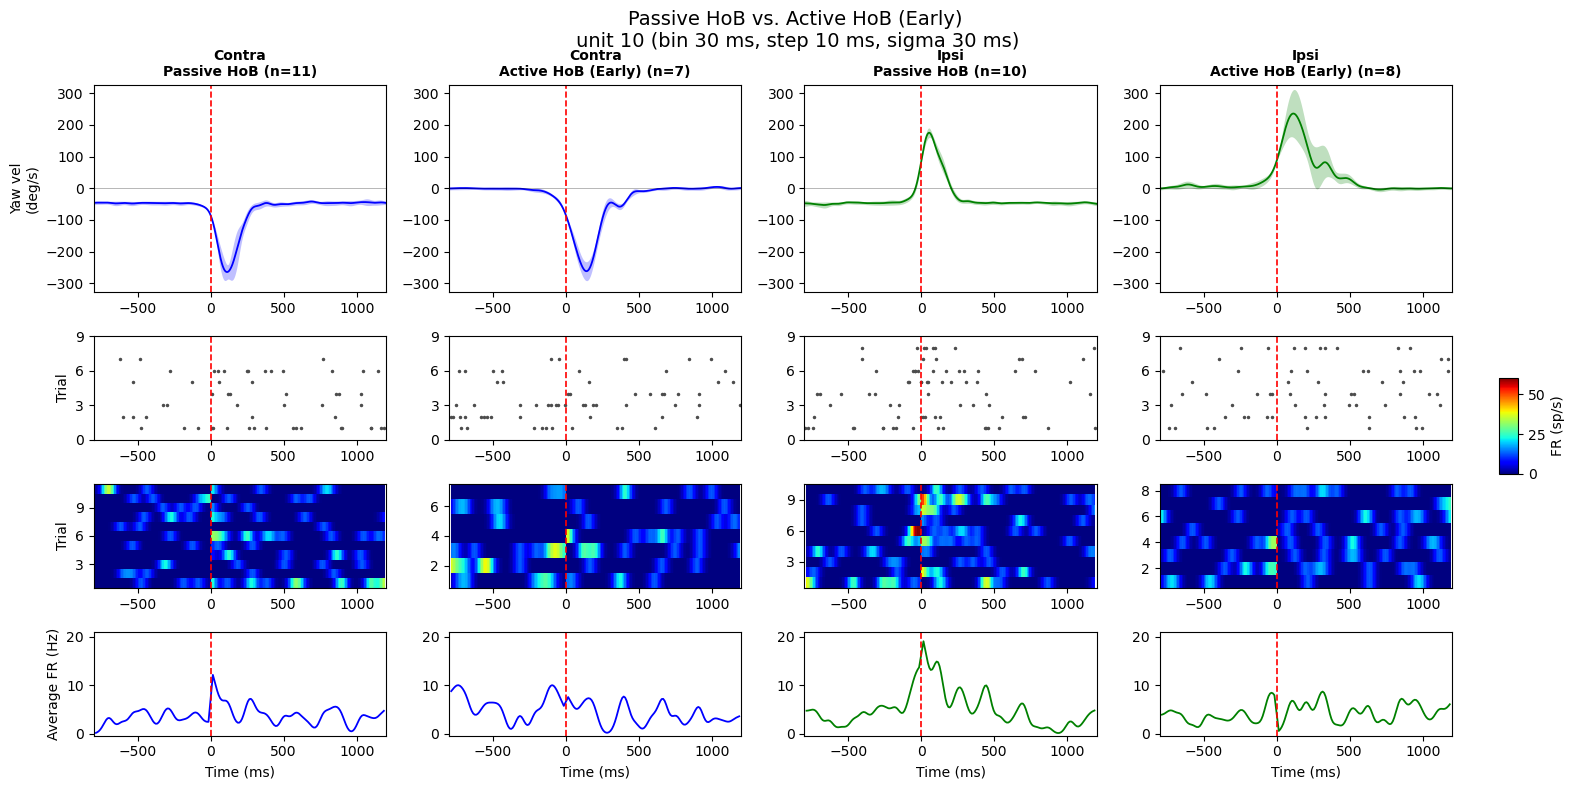

In [ ]:
uid = 10
plot_unit(uid, pick_conds("Passive HoB", "Active HoB (Early)"))
plt.show()

## Active (Early) vs Active stim

trial cap: contra n=7, ipsi n=8


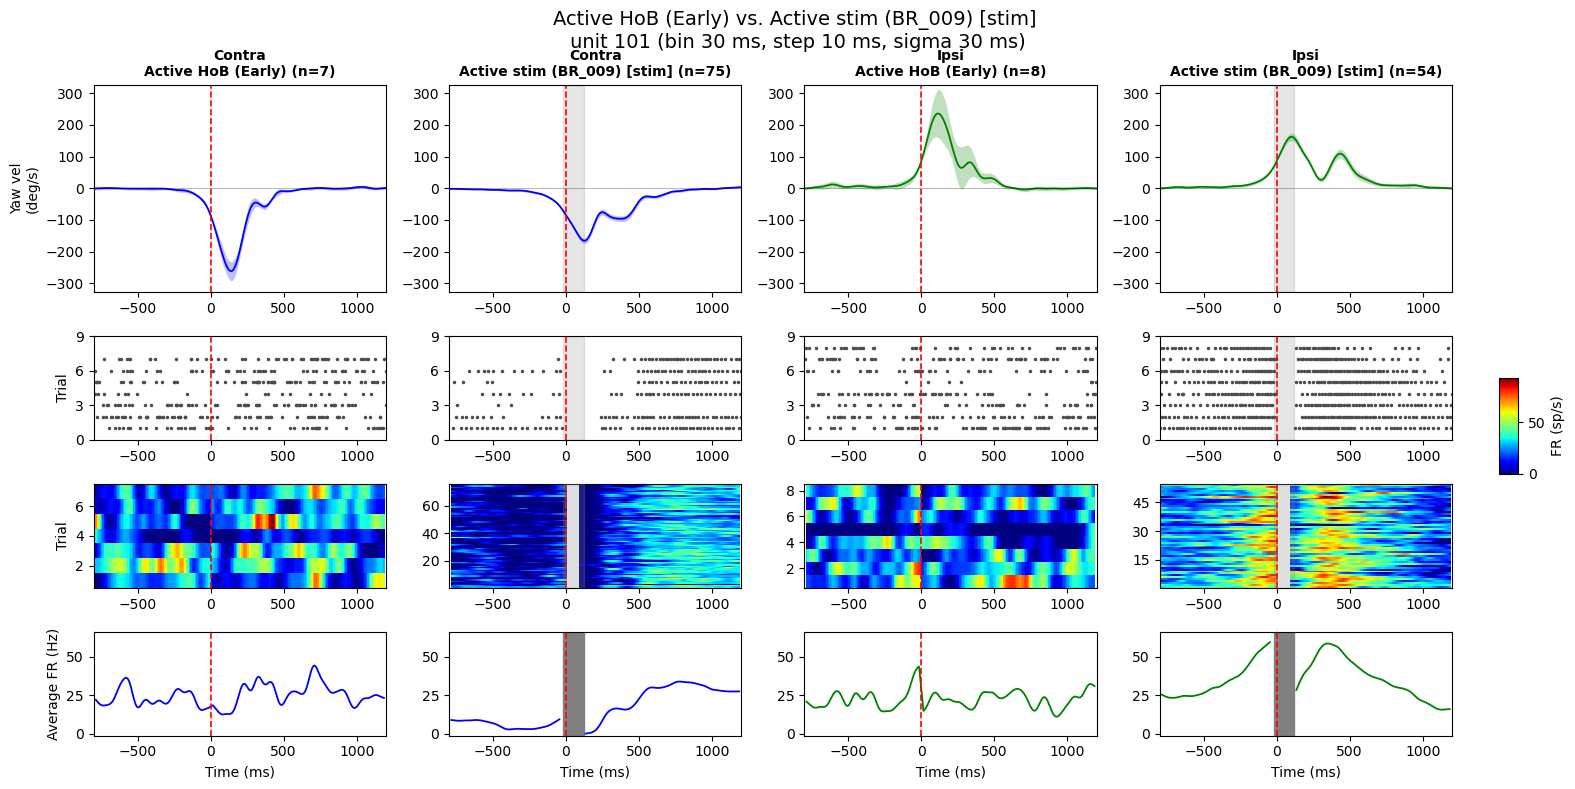

In [ ]:
uid = 101
plot_unit(uid, pick_conds("Active HoB (Early)", "Active stim (BR_009)"))
plt.show()

## Active (Late) vs Active Stim

trial cap: contra n=10, ipsi n=12


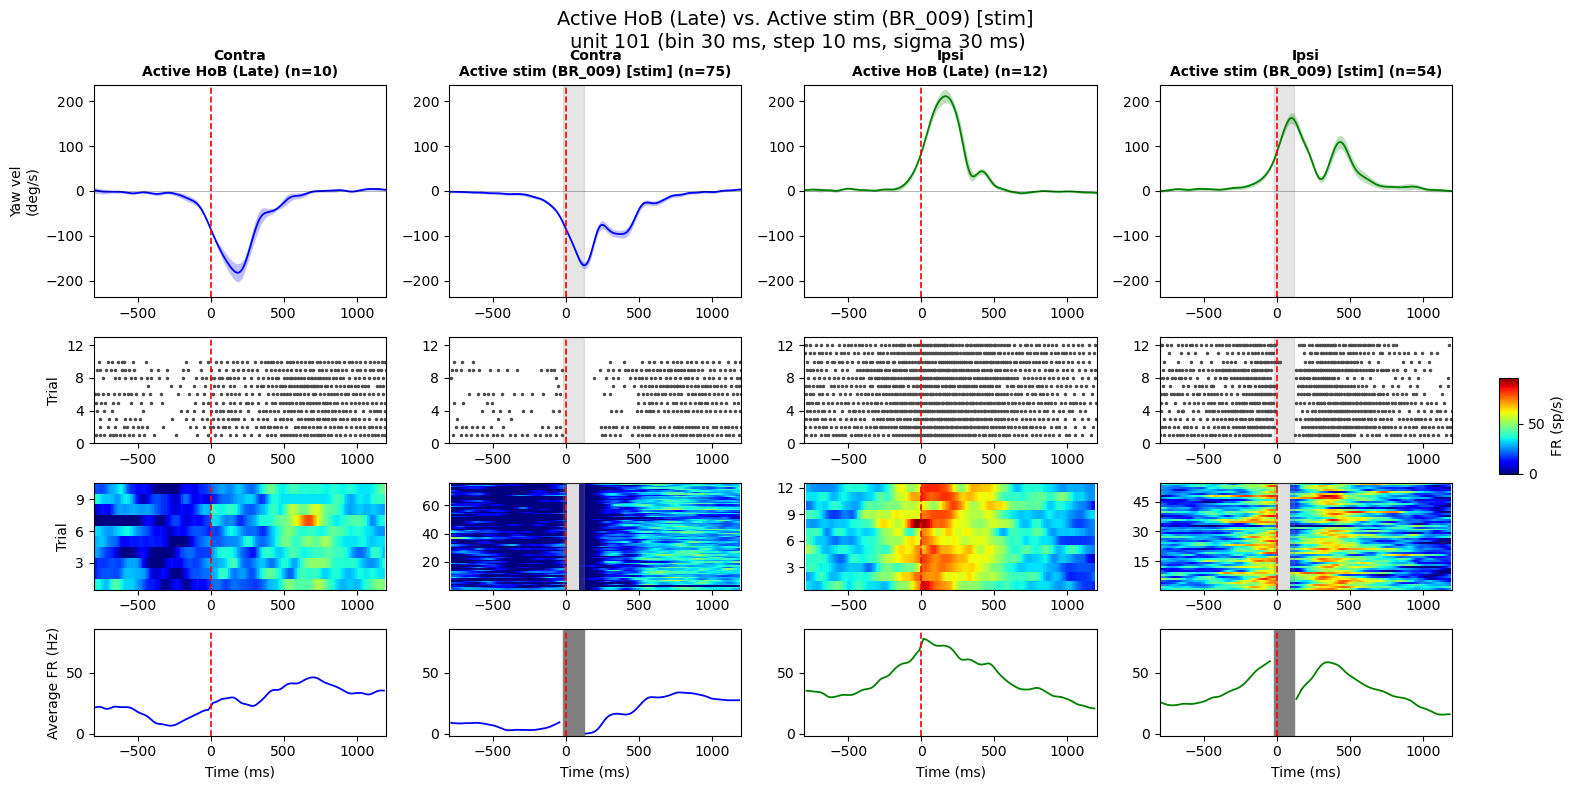

In [ ]:
uid = 101
plot_unit(uid, pick_conds("Active HoB (Late)", "Active stim (BR_009)"))
plt.show()

trial cap: contra n=5, ipsi n=5


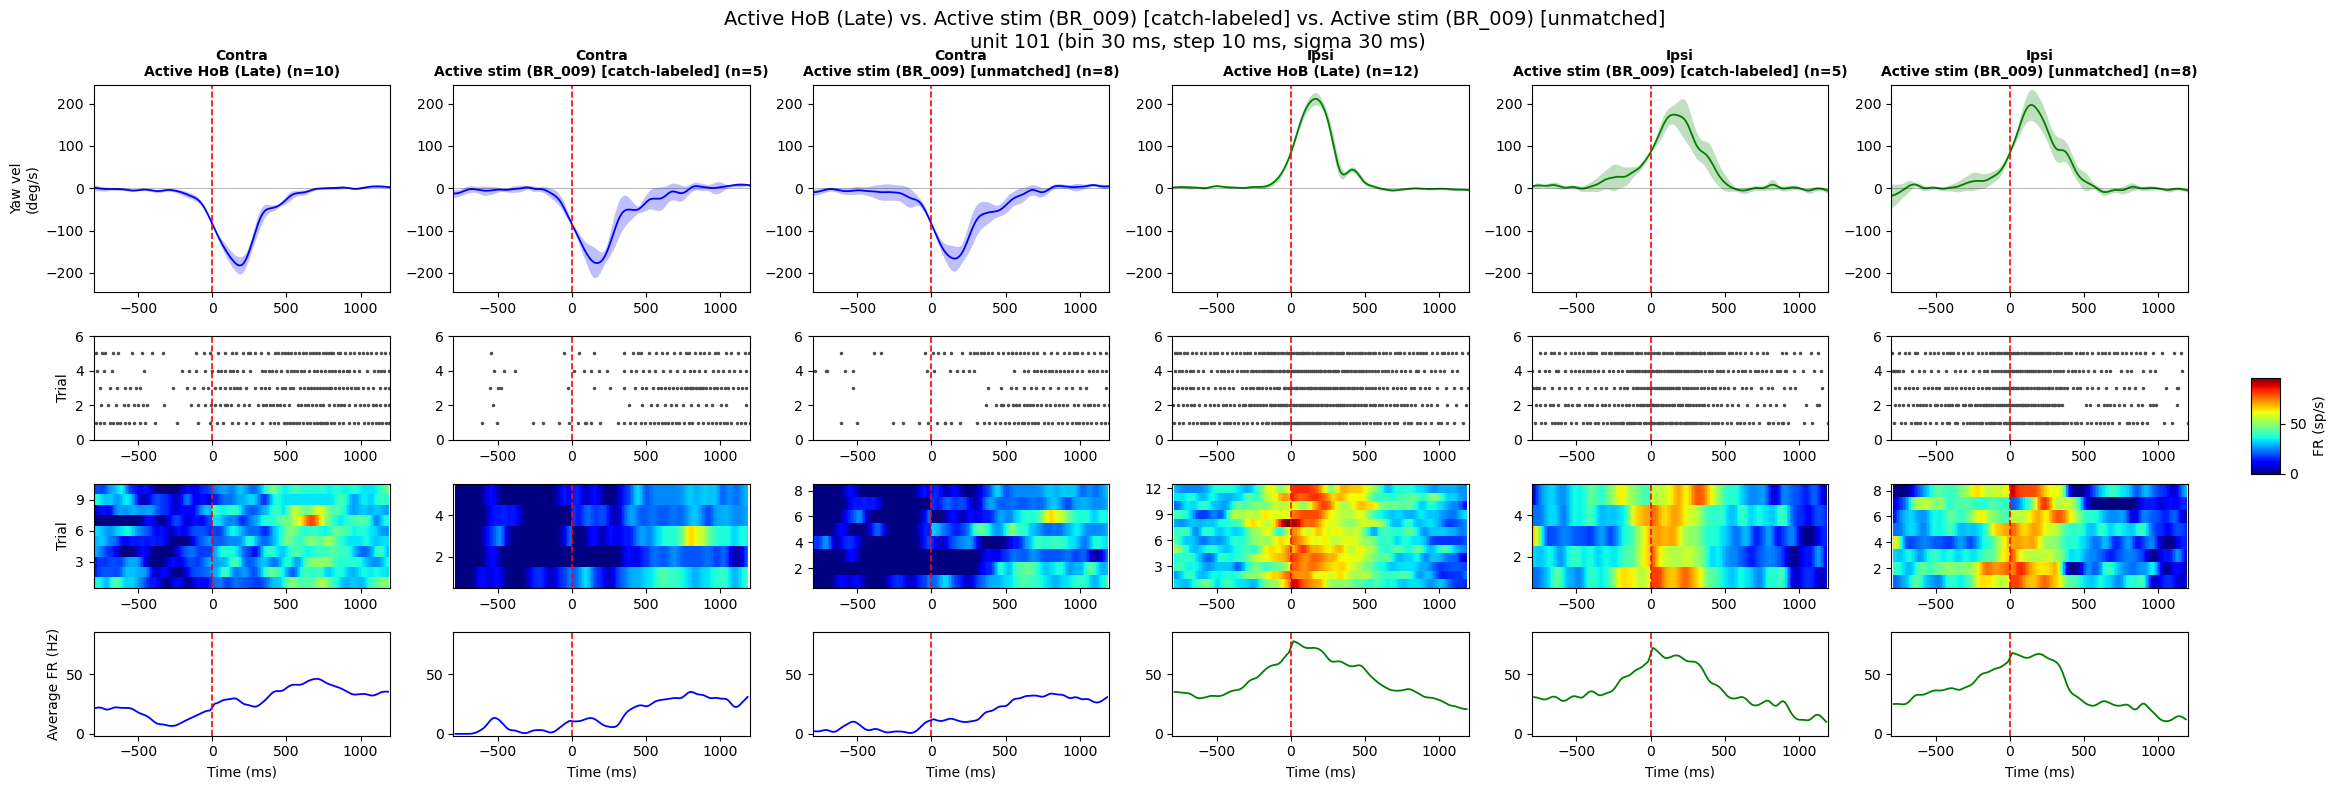

In [ ]:
plot_unit(101, pick_conds("Active HoB (Late)",
                          "Active stim (BR_009)",
                          "Active stim (BR_009) [catch]"))
plt.show()

# Plot with raw data

trial cap: contra n=10, ipsi n=12
Active HoB (Late): session BL_closed_loop_STIM_003_250528_160100, Intan_idx 3727830 samples, blanked found
Active HoB (Late): skipped trials 10 (out of range), 11 (out of range)
Active stim (BR_009): session BL_closed_loop_STIM_003_250528_150847, Intan_idx 21534870 samples, blanked found


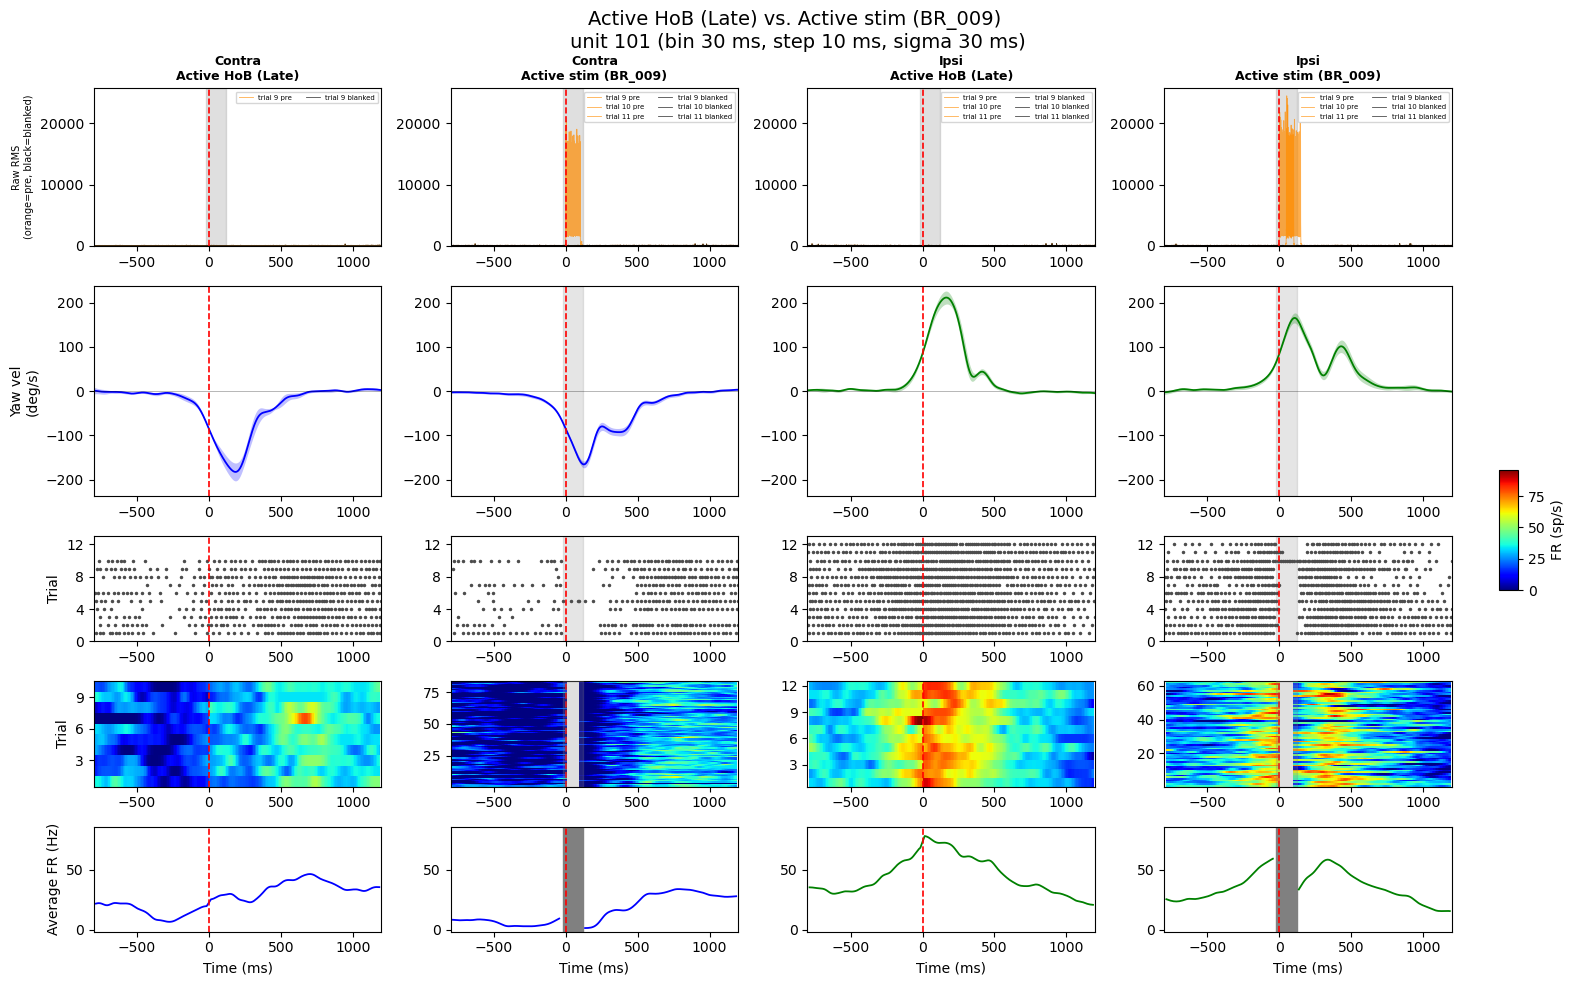

In [ ]:
plot_unit(101, pick_conds("Active HoB (Late)", "Active stim (BR_009)"),
          show_raw=True, raw_trials=[9, 10, 11])
plt.show()

# Batch save

## Passive vs Active (Early)

In [ ]:
plot_conds = [c for c in CONDITIONS if c["label"] in ("Passive HoB", "Active HoB (Early)")]
batch_save(plot_conds, available_units)

trial cap: contra n=7, ipsi n=8
Saving 194 units to /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/PassiveHoB_vs_ActiveHoBEarly


units:   0%|          | 0/194 [00:00<?, ?fig/s]

Done - 194 figures in /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/PassiveHoB_vs_ActiveHoBEarly


PosixPath('/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/PassiveHoB_vs_ActiveHoBEarly')

## Active (Early) vs Active stim

In [ ]:
plot_conds = [c for c in CONDITIONS if c["label"] in ("Active HoB (Early)", "Active stim (BR_008)")]
batch_save(plot_conds, available_units)

trial cap: contra n=7, ipsi n=8
Saving 194 units to /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBEarly_vs_ActivestimBR_008


units:   0%|          | 0/194 [00:00<?, ?fig/s]

Done - 194 figures in /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBEarly_vs_ActivestimBR_008


PosixPath('/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBEarly_vs_ActivestimBR_008')

## Active vs Active stim (Mid)

In [ ]:
batch_save(pick_conds("Active HoB (Mid)",
                          "Active stim (BR_009)"), available_units)

trial cap: contra n=14, ipsi n=13
Saving 194 units to /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBMid_vs_ActivestimBR_009[stim]


units:   0%|          | 0/194 [00:00<?, ?fig/s]

Done - 194 figures in /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBMid_vs_ActivestimBR_009[stim]


Path('/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBMid_vs_ActivestimBR_009[stim]')

## Active vs Active stim (Late)

In [ ]:
batch_save(pick_conds("Active HoB (Late)",
                          "Active stim (BR_009)"), available_units)


trial cap: contra n=10, ipsi n=12
Saving 194 units to /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBLate_vs_ActivestimBR_009[stim]


units:   0%|          | 0/194 [00:00<?, ?fig/s]

Done - 194 figures in /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBLate_vs_ActivestimBR_009[stim]


Path('/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBLate_vs_ActivestimBR_009[stim]')

In [ ]:
batch_save(pick_conds("Active HoB (Late)",
                          "Active stim (BR_009)",
                          "Active stim (BR_009) [catch]"), available_units)

trial cap: contra n=5, ipsi n=5
Saving 194 units to /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBLate_vs_ActivestimBR_009[stim]_vs_ActivestimBR_009[catch]


units:   0%|          | 0/194 [00:00<?, ?fig/s]

Done - 194 figures in /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBLate_vs_ActivestimBR_009[stim]_vs_ActivestimBR_009[catch]


Path('/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoBLate_vs_ActivestimBR_009[stim]_vs_ActivestimBR_009[catch]')

# Plot population FR

In [ ]:
# Population figure: kinematics + population FR heatmap
# Columns: [direction x condition], direction-major.
# Rows: 0 peristim kinematics (mean + 95% CI), 1 population FR heatmap.

def plot_population(pop_units, plot_conds, order_cond=None,
                    order_window_ms=(0.0, 300.0), norm="max",
                    scope="across_conditions", z_baseline_ms=(-500.0, 0.0), baseline_window_ms=(-600.0, -400.0),
                    norm_window_ms=None, cmap=None, vlim=None, vlim_pct=99.0,
                    order_by="peak_time"):
    """
    Kinematics + population FR heatmap, rows ordered by peak in a reference condition.

    Columns run direction-major: all conditions for Contra, then all for Ipsi.
    Row order is computed separately per direction, so the two direction blocks
    have different unit orderings. Panels are reindexed onto the widest time grid
    so blanked stim bins render as gaps rather than shifting the axis.

    Args:
        pop_units: unit ids, one row each.
        plot_conds: conditions to compare, left to right within each direction.
        order_cond: label of the condition that sets row order and, for zscore,
            the color scale (default: first condition).
        order_window_ms: window used to rank rows, in ms.
        norm: "max" (divide by peak FR) or "zscore" (relative to baseline).
        scope: how the per-unit scaling is derived. "across_conditions" pools all
            panels, "per_condition" scales each panel by its own stats,
            "reference" uses order_cond's stats for every panel.
        z_baseline_ms: baseline window for zscore, in ms. None uses the full trace.
        norm_window_ms: for norm="max", the window or windows in which each unit's
            peak is found, in ms. None uses the full trace. Can be either:
                (-600.0, 0.0)
            or:
                [(-600.0, -25.0), (200.0, 600.0)]
            Multiple windows are treated as their union.
        cmap: colormap name. Defaults to "bone".
        vlim: color limit for max normalization. None derives it from vlim_pct.
        vlim_pct: percentile used to derive the color limit.
        order_by: "peak_time" ranks rows by when the peak occurs in the window
            (earliest at top), "peak_amp" by peak height (largest at top).
    Returns:
        The matplotlib Figure.
    """

    # Back-compat with the old single-argument form
    if norm in ("across_conditions", "per_condition"):
        scope, norm = norm, "max"

    if norm not in ("max", "zscore"):
        raise ValueError(f"norm must be 'max' or 'zscore', got {norm!r}")

    if scope not in ("across_conditions", "per_condition", "reference"):
        raise ValueError(
            f"scope must be 'across_conditions', 'per_condition', or "
            f"'reference', got {scope!r}"
        )

    # Normalize norm_window_ms to a list of (lo, hi) windows
    if norm_window_ms is not None:
        if (
            len(norm_window_ms) == 2
            and np.isscalar(norm_window_ms[0])
            and np.isscalar(norm_window_ms[1])
        ):
            norm_windows = [tuple(norm_window_ms)]
        else:
            norm_windows = [tuple(w) for w in norm_window_ms]

        if any(len(w) != 2 for w in norm_windows):
            raise ValueError(
                "norm_window_ms must be (lo, hi) or a list of (lo, hi) windows"
            )

        norm_window_desc = " and ".join(
            f"{lo:.0f} to {hi:.0f} ms" for lo, hi in norm_windows
        )
    else:
        norm_windows = None
        norm_window_desc = "full trace"

    vlim_was_auto = vlim is None
    order_cond = order_cond or plot_conds[0]["label"]
    cond_labels = [c["label"] for c in plot_conds]
    directions = [("Contra", "contra", "b"), ("Ipsi", "ipsi", "g")]

    # Raw PSTH matrices, baseline samples, and aligned kinematics
    pop_raw = {}
    base_samp = {}
    kin = {}
    rel_s_by_cond = {}

    for dir_label, dir_key, _ in directions:
        pop_raw[dir_label] = {}
        base_samp[dir_label] = {}
        kin[dir_label] = {}

        for cond in plot_conds:
            cc = cond_cache[cond["label"]]
            events = cc["events"][dir_key]
            msb, tail = blank_params(cc["kind"])

            rows, bsamp = [], []

            for uid in pop_units:
                spk_s = cc["spikes"].get(uid, np.zeros(0))
                rates, rel_s = get_gaussian_rates(
                    spk_s, events, msb, tail
                )

                if rates.size:
                    rows.append(np.nanmean(rates, axis=0))
                else:
                    rows.append(np.full(rel_s.size, np.nan))

                # Baseline pooled over trials x bins, before the trial average
                if norm == "zscore" and rates.size:
                    rel_ms = rel_s * 1000.0

                    if z_baseline_ms is None:
                        bmask = np.ones(rel_ms.size, bool)
                    else:
                        bmask = (
                            (rel_ms >= z_baseline_ms[0])
                            & (rel_ms <= z_baseline_ms[1])
                        )

                    if not bmask.any():
                        bmask = np.ones(rel_ms.size, bool)

                    vals = rates[:, bmask].ravel()
                    bsamp.append(vals[np.isfinite(vals)])
                else:
                    bsamp.append(np.zeros(0))

            rel_s_by_cond[cond["label"]] = rel_s
            pop_raw[dir_label][cond["label"]] = np.vstack(rows)
            base_samp[dir_label][cond["label"]] = bsamp

            # Kinematics, same alignment as the per-unit figure
            rel_vel_s, vel_segs = get_aligned_vel(
                cc["t_vel"], cc["vel"], events, WIN_PRE_S, WIN_POST_S
            )

            vel_mean, vel_lo, vel_hi = mean_ci(vel_segs)

            kin[dir_label][cond["label"]] = dict(
                rel_vel_s=rel_vel_s,
                mean=vel_mean,
                lo=vel_lo,
                hi=vel_hi,
                n=vel_segs.shape[0],
            )

    # Normalize
    def _peak_over(mat, rel_ms):
        """Baseline-subtracted per-unit peak within one or more normalization windows."""

        # Baseline firing rate from the pre-event period
        baseline_mask = (rel_ms >= -600.0) & (rel_ms <= -25.0)

        if baseline_mask.any():
            baseline = np.nanmean(mat[:, baseline_mask], axis=1)
        else:
            baseline = np.nanmean(mat, axis=1)

        # Subtract baseline from the entire trace
        mat_bs = mat - baseline[:, None]

        # Find normalization peak
        if norm_windows is None:
            sub = mat_bs
        else:
            mask = np.zeros(rel_ms.size, dtype=bool)

            for lo, hi in norm_windows:
                mask |= (rel_ms >= lo) & (rel_ms <= hi)

            sub = mat_bs[:, mask] if mask.any() else mat_bs

        peak = np.array([
            np.nanmax(r) if np.isfinite(r).any() else np.nan
            for r in sub
        ])

        return np.where(
            np.isfinite(peak) & (peak > 1e-9),
            peak,
            1.0,
        )[:, None]

    pop_norm = {}

    def _baseline_subtract_and_peak(mat, rel_ms):
        """Subtract baseline and find the normalization peak."""

        baseline_mask = (rel_ms >= -600.0) & (rel_ms <= -25.0)

        if baseline_mask.any():
            baseline = np.nanmean(mat[:, baseline_mask], axis=1)
        else:
            baseline = np.nanmean(mat, axis=1)

        mat_bs = mat - baseline[:, None]

        if norm_windows is None:
            sub = mat_bs
        else:
            mask = np.zeros(rel_ms.size, dtype=bool)

            for lo, hi in norm_windows:
                mask |= (rel_ms >= lo) & (rel_ms <= hi)

            sub = mat_bs[:, mask] if mask.any() else mat_bs

        peak = np.array([
            np.nanmax(r) if np.isfinite(r).any() else np.nan
            for r in sub
        ])

        peak = np.where(
            np.isfinite(peak) & (peak > 1e-9),
            peak,
            1.0,
        )

        return mat_bs, peak[:, None]
    for dir_label in pop_raw:
        pop_norm[dir_label] = {}

        if norm == "max":
            if scope == "per_condition":
                for cl in cond_labels:
                    mat = pop_raw[dir_label][cl]
                    rel_ms = rel_s_by_cond[cl] * 1000.0
                    mat_bs, peak = _baseline_subtract_and_peak(mat, rel_ms)
                    pop_norm[dir_label][cl] = mat_bs / peak

            elif scope == "across_conditions":
                # Step 1: Baseline-subtract each condition's matrix independently
                mats_bs = {}
                peaks_list = []
                for cl in cond_labels:
                    mat = pop_raw[dir_label][cl]
                    rel_ms = rel_s_by_cond[cl] * 1000.0
                    
                    # _baseline_subtract_and_peak returns baseline-subtracted matrix and peak
                    mat_bs, peak = _baseline_subtract_and_peak(mat, rel_ms)
                    mats_bs[cl] = mat_bs
                    peaks_list.append(peak)

                # Step 2: Pool peaks across conditions to get the global maximum per unit
                shared_peak = np.nanmax(np.hstack(peaks_list), axis=1, keepdims=True)

                # Step 3: Scale all baseline-subtracted matrices by the shared peak
                pop_norm[dir_label] = {
                    cl: mats_bs[cl] / shared_peak
                    for cl in cond_labels
                }

            elif scope == "reference":
                # Baseline-subtract and scale using order_cond's baseline and peak
                ref_mat = pop_raw[dir_label][order_cond]
                ref_rel_ms = rel_s_by_cond[order_cond] * 1000.0
                _, ref_peak = _baseline_subtract_and_peak(ref_mat, ref_rel_ms)
                
                pop_norm[dir_label] = {}
                for cl in cond_labels:
                    mat = pop_raw[dir_label][cl]
                    rel_ms = rel_s_by_cond[cl] * 1000.0
                    mat_bs, _ = _baseline_subtract_and_peak(mat, rel_ms)
                    pop_norm[dir_label][cl] = mat_bs / ref_peak

    # Row order from the reference condition's window
    rel_ms_order = rel_s_by_cond[order_cond] * 1000.0

    order_mask = (
        (rel_ms_order >= order_window_ms[0])
        & (rel_ms_order <= order_window_ms[1])
    )

    pop_data, row_units = {}, {}

    win_ms = rel_ms_order[order_mask]

    for dir_label in pop_norm:
        ref_mat = pop_norm[dir_label][order_cond]
        win = ref_mat[:, order_mask]

        # A row with no finite data, or one that never rises above its own floor,
        # has no meaningful peak time; both sink to the bottom.
        finite = np.array([
            np.isfinite(r).any()
            for r in win
        ])

        span = np.array([
            (np.nanmax(r) - np.nanmin(r)) if f else 0.0
            for r, f in zip(win, finite)
        ])

        flat = ~finite | (span < 1e-9)

        if order_by == "peak_time":
            key = np.array([
                win_ms[np.nanargmax(r)] if not fl else np.inf
                for r, fl in zip(win, flat)
            ])

            order = np.argsort(key)

        elif order_by == "peak_amp":
            key = np.array([
                np.nanmax(r) if not fl else -np.inf
                for r, fl in zip(win, flat)
            ])

            order = np.argsort(key)[::-1]

        else:
            raise ValueError(
                f"order_by must be 'peak_time' or 'peak_amp', got {order_by!r}"
            )

        if flat.any():
            print(
                f"{dir_label}: {int(flat.sum())} flat/empty rows moved to bottom "
                f"({[pop_units[i] for i in np.where(flat)[0]]})"
            )

        pop_data[dir_label] = {
            cl: pop_norm[dir_label][cl][order]
            for cl in cond_labels
        }

        row_units[dir_label] = [
            pop_units[i] for i in order
        ]

    # Color scaling depends on the normalization
    clip_frac = {}

    if norm == "max":
        cmap = cmap or "bone"

        if norm_window_ms is None:
            vmin, vmax = 0.0, 1.0
            cbar_label = "Norm. FR (peak)"
            cbar_extend = "neither"

        else:
            if vlim is None:
                allv = np.concatenate([
                    pop_data[d][cl].ravel()
                    for d in pop_data
                    for cl in cond_labels
                ])

                allv = allv[np.isfinite(allv)]

                v = (
                    np.percentile(allv, vlim_pct)
                    if allv.size
                    else 1.0
                )

                vlim = (
                    float(v)
                    if np.isfinite(v) and v > 0
                    else 1.0
                )

            vmin, vmax = 0.0, vlim

            cbar_label = f"FR / peak in {norm_window_desc}"
            cbar_extend = "max"

            for cl in cond_labels:
                vals = np.concatenate([
                    pop_data[d][cl].ravel()
                    for d in pop_data
                ])

                vals = vals[np.isfinite(vals)]

                clip_frac[cl] = (
                    float(np.mean(vals > vlim))
                    if vals.size
                    else 0.0
                )

    else:
        if vlim is None:
            # Scale set by the reference condition only, both directions
            refz = np.concatenate([
                pop_data[d][order_cond].ravel()
                for d in pop_data
            ])

            refz = np.abs(refz[np.isfinite(refz)])

            v = (
                np.percentile(refz, vlim_pct)
                if refz.size
                else 1.0
            )

            vlim = (
                float(v)
                if np.isfinite(v) and v > 0
                else 1.0
            )

        vmin, vmax = -vlim, vlim
        cmap = cmap or "bone"
        cbar_label = f"FR (z), scale from {order_cond}"
        cbar_extend = "both"

        for cl in cond_labels:
            vals = np.concatenate([
                pop_data[d][cl].ravel()
                for d in pop_data
            ])

            vals = vals[np.isfinite(vals)]

            clip_frac[cl] = (
                float(np.mean(np.abs(vals) > vlim))
                if vals.size
                else 0.0
            )

    # Shared velocity y-limits across every column
    vel_absmax = 0.0

    for dir_label in kin:
        for cl in cond_labels:
            bounds = np.concatenate([
                kin[dir_label][cl]["lo"],
                kin[dir_label][cl]["hi"],
            ])

            bounds = bounds[np.isfinite(bounds)]

            if bounds.size:
                vel_absmax = max(
                    vel_absmax,
                    np.max(np.abs(bounds)),
                )

    vel_ylim = (
        (-vel_absmax * 1.05, vel_absmax * 1.05)
        if vel_absmax > 0
        else (-500, 500)
    )

    # Widest grid wins; blanked panels get NaN where they have no bins
    full_rel_ms = (
        max(rel_s_by_cond.values(), key=lambda a: a.size) * 1000.0
    )

    xlim = (
        full_rel_ms[0],
        full_rel_ms[-1],
    )

    n_units = len(pop_units)

    # Column spec, direction-major
    columns = [
        dict(
            dir_label=dl,
            color=col,
            cond=cond,
        )
        for dl, _, col in directions
        for cond in plot_conds
    ]

    n_cols = len(columns)
    block = len(plot_conds)

    fig_h = 3.0 + max(
        4.0,
        0.16 * n_units,
    )

    fig, axes = plt.subplots(
        2,
        n_cols,
        figsize=(4 * n_cols, fig_h),
        squeeze=False,
        gridspec_kw={"height_ratios": [1, 2]},
    )

    last_im = None

    for c, colspec in enumerate(columns):
        dir_label = colspec["dir_label"]
        cond = colspec["cond"]
        cl = cond["label"]
        is_stim = cond["kind"] == "stim"
        first_of_block = (c % block == 0)

        ax_vel = axes[0][c]
        k = kin[dir_label][cl]

        if k["mean"].size:
            t_ms = k["rel_vel_s"] * 1000.0

            ax_vel.fill_between(
                t_ms,
                k["lo"],
                k["hi"],
                color=colspec["color"],
                alpha=0.2,
                lw=0,
            )

            ax_vel.plot(
                t_ms,
                k["mean"],
                color=colspec["color"],
                lw=1.3,
            )

        ax_vel.axhline(
            0,
            color="k",
            lw=0.5,
            alpha=0.4,
        )

        ax_vel.axvline(
            0,
            color="r",
            ls="--",
            lw=1.2,
        )

        if is_stim:
            ax_vel.axvspan(
                -STIM_MS_BEFORE,
                STIM_DUR_MS + STIM_TAIL_MS,
                color="grey",
                alpha=0.5,
                zorder=0,
            )

        ax_vel.set_xlim(xlim)
        ax_vel.set_ylim(vel_ylim)

        ax_vel.set_title(
            f"{dir_label}\n{cl} (n={k['n']})",
            fontsize=10,
            fontweight="bold",
        )

        if first_of_block:
            ax_vel.set_ylabel("Yaw vel\n(deg/s)")
        else:
            ax_vel.set_yticklabels([])

        ax_heat = axes[1][c]

        mat = pop_data[dir_label][cl]

        cond_rel_ms = rel_s_by_cond[cl] * 1000.0

        full_mat = np.full(
            (n_units, full_rel_ms.size),
            np.nan,
        )

        col_idx = np.abs(
            full_rel_ms[None, :] - cond_rel_ms[:, None]
        ).argmin(axis=1)

        full_mat[:, col_idx] = mat

        last_im = ax_heat.pcolormesh(
            full_rel_ms,
            np.arange(n_units),
            full_mat,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            shading="nearest",
        )

        ax_heat.axvline(
            0,
            color="r",
            ls="--",
            lw=1.2,
        )

        if is_stim:
            ax_heat.axvspan(
                -STIM_MS_BEFORE,
                STIM_DUR_MS + STIM_TAIL_MS,
                color="grey",
                alpha=1,
                zorder=3,
            )

        ax_heat.set_xlim(xlim)
        ax_heat.set_ylim(
            n_units - 0.5,
            -0.5,
        )

        if first_of_block:
            ax_heat.set_yticks(range(n_units))
            ax_heat.set_yticklabels(
                row_units[dir_label],
                fontsize=6,
            )
            ax_heat.set_ylabel(
                f"Unit ID ({dir_label} order)"
            )
        else:
            ax_heat.set_yticks([])

        ax_heat.set_xlabel("Time (ms)")

    # Build the title
    cond_title = " vs. ".join(cond_labels)

    lo, hi = order_window_ms

    if norm == "max":
        if norm_window_ms is None:
            win_desc = "full-trace peak"
        else:
            win_desc = f"{norm_window_desc}"

        norm_desc = (
            f"normalized to max in {win_desc}"
            # f"{scope.replace('_', ' ')}"
        )

        if norm_window_ms is None:
            clip_desc = ""
        else:
            clip_desc = ", ".join(
                f"{100 * f:.1f}% {cl}"
                for cl, f in clip_frac.items()
            )

    else:
        base_desc = (
            "full trace"
            if z_baseline_ms is None
            else f"{z_baseline_ms[0]:.0f} to {z_baseline_ms[1]:.0f} ms"
        )

        scope_desc = {
            "reference": f"baseline from {order_cond}",
            "across_conditions": "pooled baseline",
            "per_condition": "per-condition baseline",
        }[scope]

        norm_desc = (
            f"z-scored vs. {base_desc} baseline, "
            f"{scope_desc}"
        )

        scale_src = (
            f"p{vlim_pct:g} of |z| in {order_cond}"
            if vlim_was_auto
            else "manual"
        )

        clip_desc = ", ".join(
            f"{100 * f:.1f}% {cl}"
            for cl, f in clip_frac.items()
        )

    title_str = (
        f"Population FR ({norm_desc})\n"
        f"{cond_title}\n"
        f"ordered by {order_by.replace('_', ' ')} "
        f"in {lo:.0f}-{hi:.0f} ms of {order_cond}\n"
        f"bin {BIN_MS:.0f} ms, step {STEP_MS:.0f} ms, "
        f"sigma {SIGMA_MS:.0f} ms, n={n_units} units"
    )

    # Reserve title space in inches, not as a fraction of figure height
    title_fs = 12
    pad_in = 0.20
    fig_h_actual = fig.get_figheight()

    title_in = (
        (title_str.count("\n") + 1)
        * title_fs
        * 1.4
        / 72.0
        + 2 * pad_in
    )

    top_frac = max(
        0.55,
        1.0 - title_in / fig_h_actual,
    )

    fig.tight_layout(
        rect=[0, 0, 0.92, top_frac]
    )

    if last_im is not None:
        cbar_ax = fig.add_axes(
            [0.94, 0.25, 0.012, 0.3]
        )

        fig.colorbar(
            last_im,
            cax=cbar_ax,
            label=cbar_label,
            extend=cbar_extend,
        )

    fig.suptitle(
        title_str,
        fontsize=title_fs,
        va="top",
        y=1.0 - pad_in / fig_h_actual,
    )

    return fig

## Population: Passive vs Active (Early), all responsive units

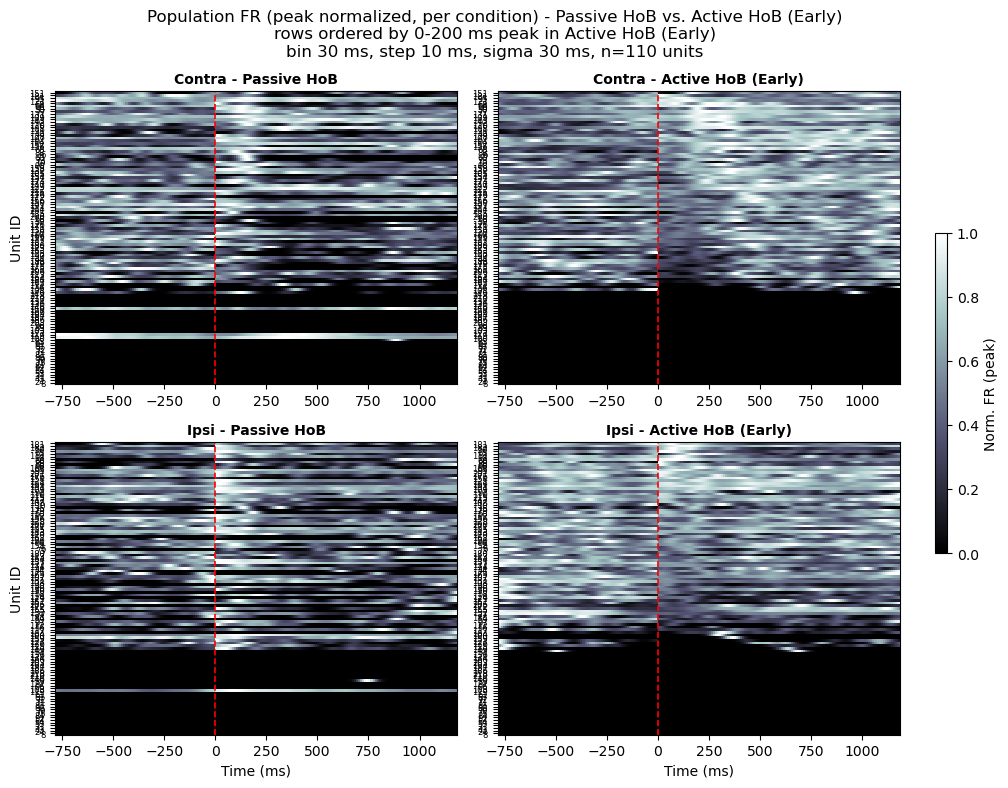

In [ ]:
pop_units_input = [6, 8, 10, 24, 31, 40, 43, 44, 50, 52, 53, 54, 56, 58, 59, 60, 61, 65, 66, 67, 68, 71, 72, 73, 75, 77, 79, 80, 81, 83, 84, 88, 89, 92, 94, 95, 96, 97, 98, 100, 103, 104, 105, 107, 108, 109, 110, 111, 112, 113, 114, 117, 119, 120, 121, 122, 123, 125, 126, 127, 128, 129, 130, 131, 132, 134, 135, 136, 137, 143, 146, 147, 149, 150, 151, 152, 154, 155, 156, 158, 159, 162, 163, 164, 165, 166, 171, 172, 174, 175, 176, 179, 180, 181, 182, 184, 186, 187, 188, 190, 191, 194, 199, 200, 201, 203, 206, 210, 215, 218]

plot_conds = [c for c in CONDITIONS if c["label"] in ("Passive HoB", "Active HoB (Early)")]
plot_population(pop_units_input, plot_conds,
                order_cond="Active HoB (Early)", order_window_ms=(0.0, 200.0),
                norm="per_condition")
plt.show()

## Population: Active (Early) vs Active stim, selected units

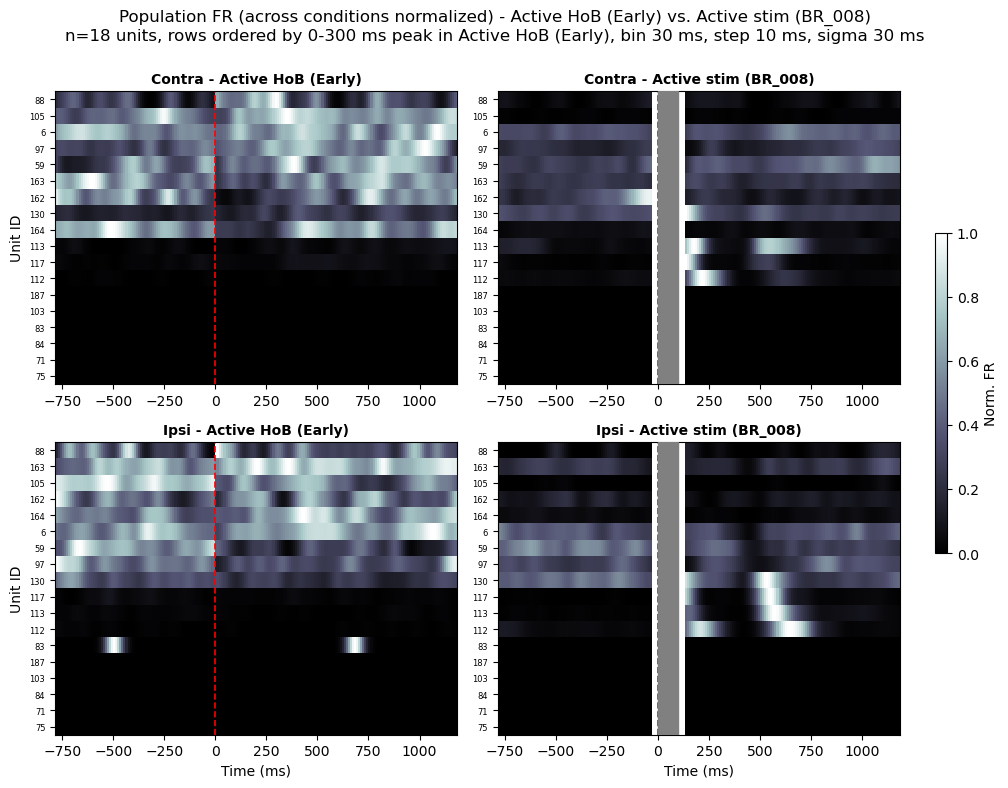

In [ ]:
pop_units_input = [6, 59, 71, 75, 83, 84, 88, 97, 103, 105, 112, 113, 117, 130, 162, 163, 164, 187]

plot_conds = [c for c in CONDITIONS if c["label"] in ("Active HoB (Early)", "Active stim (BR_009)")]
plot_population(pop_units_input, plot_conds,
                order_cond="Active HoB (Early)", order_window_ms=(0.0, 300.0),
                norm="across_conditions")
plt.show()

## Population: Active (Late) vs Active stim, selected units

Contra: 3 flat/empty rows moved to bottom ([85, 86, 117])
Ipsi: 3 flat/empty rows moved to bottom ([85, 86, 117])


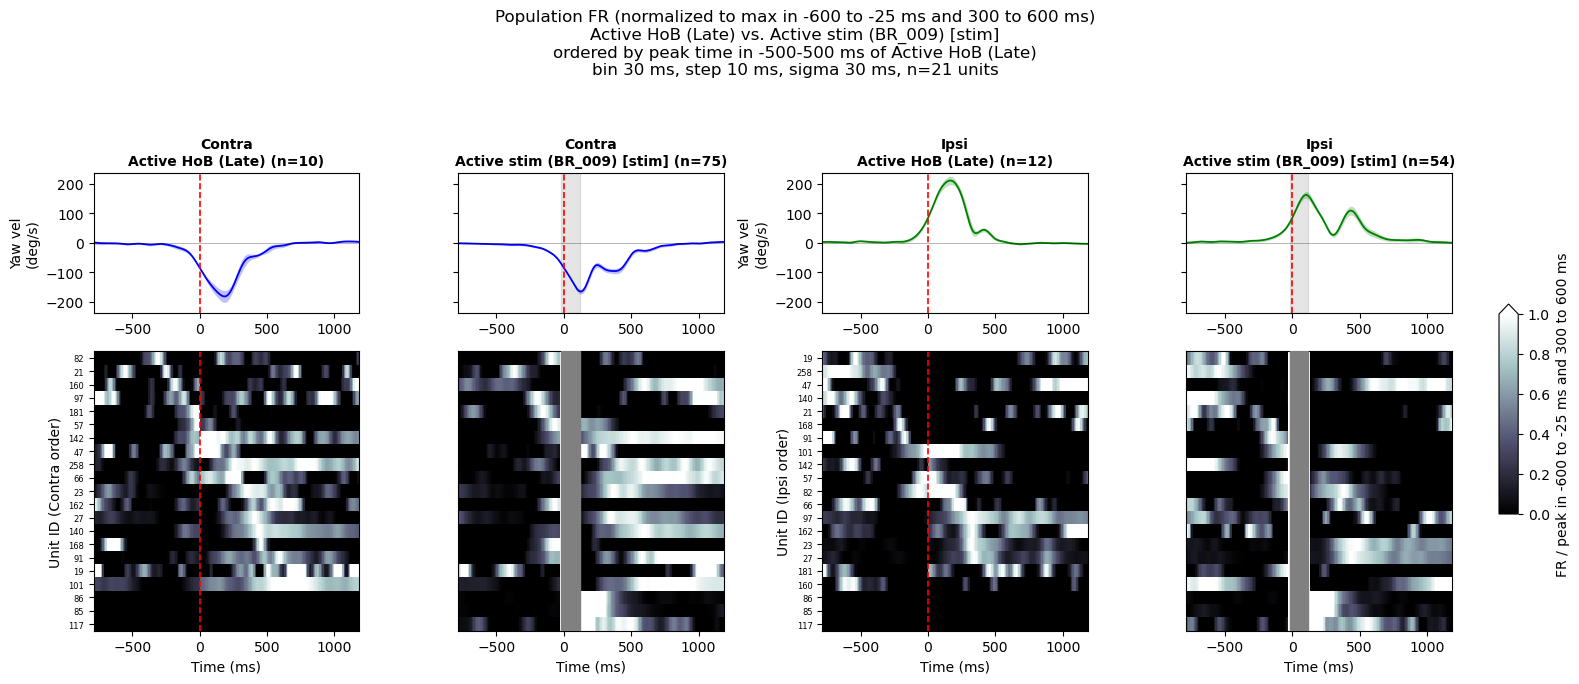

In [ ]:
pop_units_input = [19, 21, 23, 27, 47, 57, 66, 82, 85, 86, 91, 97, 101, 117, 140, 142, 160, 162, 168, 181, 258]
# pop_units_input = [6, 19, 21, 23, 26, 27, 29, 30, 34, 39, 40, 41, 42, 47, 57, 58, 59, 60, 65, 66, 82, 85, 86, 91, 97, 101, 117, 121, 138, 139, 140, 142, 147, 160, 162, 168, 170, 172, 181, 183, 190, 199, 250, 253, 258]
# pop_units_input = [7, 55, 73, 76, 94, 95, 109, 110, 112, 113, 114, 115, 116, 118, 120, 123, 125, 126, 128, 130, 131, 154, 156, 171, 188, 189, 193, 197, 213, 214, 217, 219, 222, 227, 241, 256, 257, 259]

plot_population(pop_units_input, pick_conds("Active HoB (Late)", "Active stim (BR_009)"),
                order_cond="Active HoB (Late)", order_window_ms=(-500.0, 500.0),
                norm="per_condition", norm_window_ms=[(-600.0, -25.0), (300.0, 600.0)], vlim=1.0)
plt.show()

## Try Z score

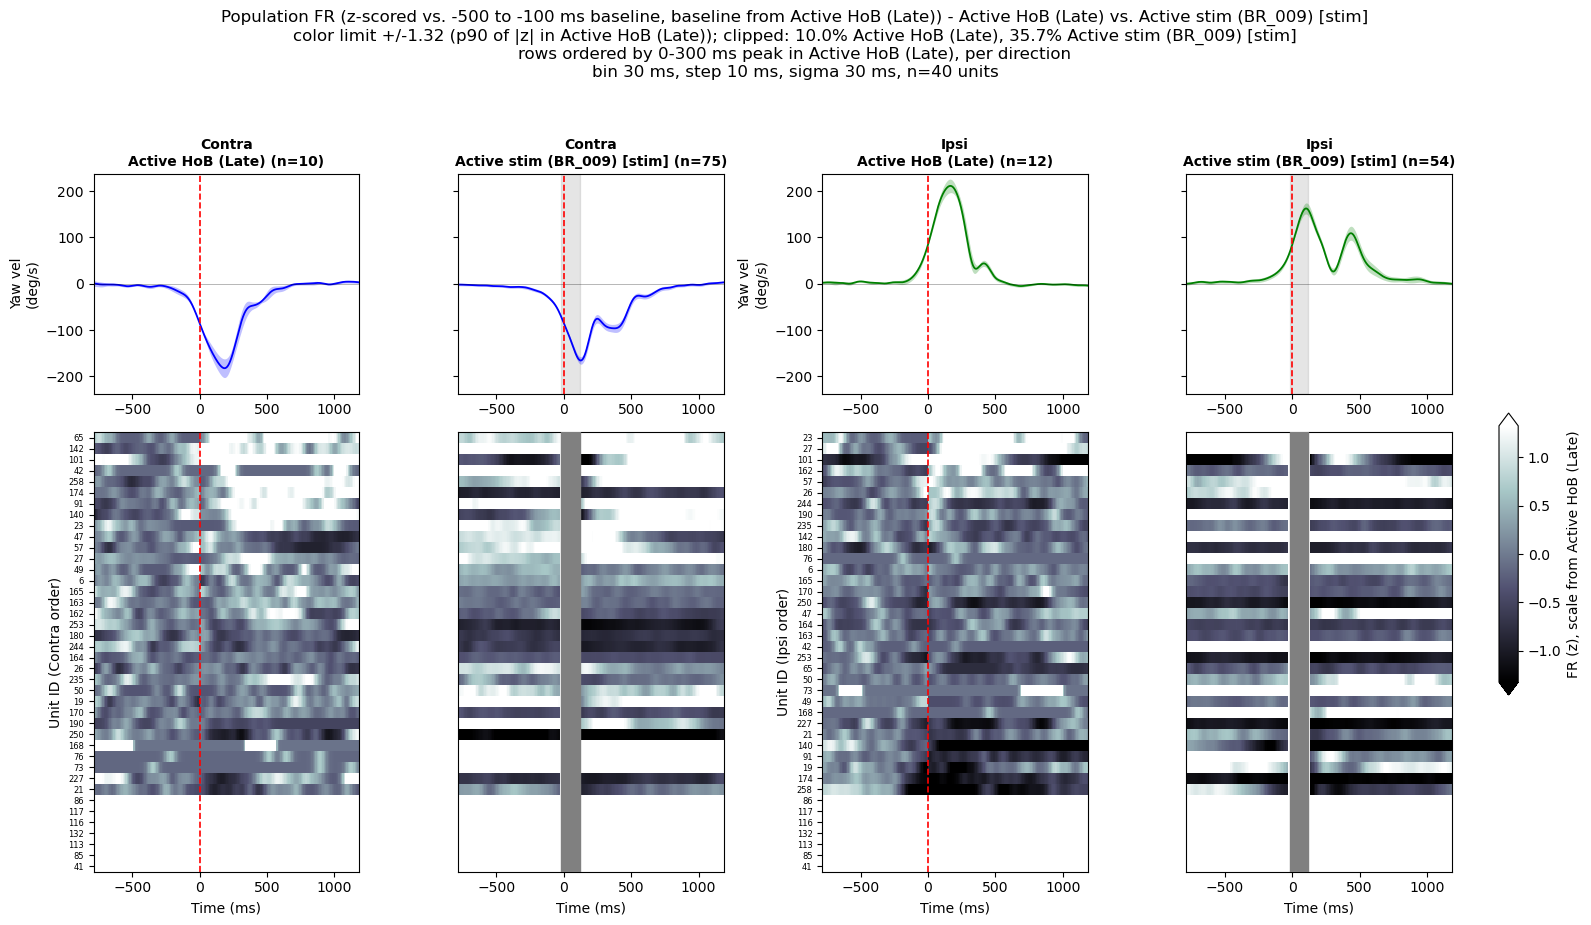

In [ ]:
plot_population(pop_units_input, pick_conds("Active HoB (Late)", "Active stim (BR_009)"),
                order_cond="Active HoB (Late)", order_window_ms=(0.0, 300.0),
                norm="zscore", scope="reference", vlim_pct=90)
plt.show()

# Poisson LDS

In [7]:
# Poisson LDS: raw spike counts per unit, non-overlapping bins
# The heatmap path uses Gaussian-smoothed overlapping bins; neither is valid
# for a Poisson likelihood, so this rebins from scratch.

import jax
import jax.numpy as jnp
import jax.random as jr
import optax
from jax import vmap, value_and_grad, jit
from jax.nn import softplus
from tensorflow_probability.substrates.jax.distributions import Poisson

from dynamax.generalized_gaussian_ssm import (
    ParamsGGSSM, GeneralizedGaussianSSM, EKFIntegrals,
    conditional_moments_gaussian_smoother as cmgs,
)

LDS_BIN_MS = 10.0
LDS_STEP_MS = 10.0
LDS_WIN_MS = (-800.0, 1200.0)
LDS_CONTROL = "Active HoB (Late)"
LDS_STIM = "Active stim (BR_009) [stim]"
LDS_CATCH = "Active stim (BR_009) [catch]"
LDS_DIRS = ("contra", "ipsi")

def get_unit_counts(cond_label, dir_key, units, bin_ms=LDS_BIN_MS, win_ms=LDS_WIN_MS):
    """
    Raw spike counts per unit on a common event-aligned bin grid.

    The stim blank window is applied to every condition, baseline included, so
    all conditions land on the same bin centers and can be stacked.

    Args:
        cond_label: CONDITIONS label to pull from cond_cache.
        dir_key: "contra" or "ipsi".
        units: unit ids, one observation dimension each.
        bin_ms: bin width; no step_ms means non-overlapping bins.
        win_ms: (pre, post) window in ms.
    Returns:
        counts (n_trials, n_units, n_bins), rel_ms bin centers.
    """
    cc = cond_cache[cond_label]
    events = cc["events"][dir_key]
    if events.size == 0:
        return np.zeros((0, len(units), 0)), np.zeros(0)
    peaks_ms = {i: cc["spikes"].get(uid, np.zeros(0)) * 1000.0
                for i, uid in enumerate(units)}
    msb, tail = (STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS)  # force, so grids match
    counts, rel_ms, _, _ = rcp.bin_counts_around_stim(
        peaks_ms, bin_ms, events * 1000.0, msb, tail, win_ms, step_ms=LDS_STEP_MS
    )        
    return np.asarray(counts, float), np.asarray(rel_ms, float)


# Population from the heatmap step
lds_units = [6, 19, 21, 23, 26, 27, 29, 30, 34, 39, 40, 41, 42, 47, 57, 58, 59, 60, 65, 66, 82, 85, 86, 91, 97, 101, 117, 121, 138, 139, 140, 142, 147, 160, 162, 168, 170, 172, 181, 183, 190, 199, 250, 253, 258]

blocks = {}
for cl in (LDS_CONTROL, LDS_STIM):
    for dk in LDS_DIRS:
        counts, rel_ms = get_unit_counts(cl, dk, lds_units)
        blocks[(cl, dk)] = counts
        print(f"{cl:24s} {dk:6s} trials={counts.shape[0]:3d} bins={counts.shape[2]}")

centers_ms = rel_ms
n_bins = centers_ms.size

# Drop units that are silent in any block; a zero row breaks the log(d) init
tot = np.stack([b.sum(axis=(0, 2)) for b in blocks.values()])  # (n_blocks, n_units)
keep = np.all(tot > 0, axis=0)
print(f"\nkeeping {keep.sum()}/{len(lds_units)} units")
if not keep.all():
    print("dropped:", [u for u, k in zip(lds_units, keep) if not k])
lds_units_kept = [u for u, k in zip(lds_units, keep) if k]
blocks = {k: v[:, keep, :] for k, v in blocks.items()}

Active HoB (Late)        contra trials= 10 bins=186
Active HoB (Late)        ipsi   trials= 12 bins=186
Active stim (BR_009) [stim] contra trials= 75 bins=186
Active stim (BR_009) [stim] ipsi   trials= 54 bins=186

keeping 40/45 units
dropped: [29, 41, 85, 86, 117]


In [13]:
# Stack all four blocks; input is a scalar stim indicator at the pulse bin

obs_list, u_list, cond_lab, dir_lab = [], [], [], []
ir_idx = int(np.argmin(np.abs(centers_ms)))  # first bin after the blank

for (cl, dk), counts in blocks.items():
    if counts.shape[0] == 0:
        continue
    obs_list.append(counts.transpose(0, 2, 1))  # (trials, bins, units)
    u = np.zeros((counts.shape[0], n_bins, 1))
    if cl == LDS_STIM:
        u[:, ir_idx, 0] = 1.0
    u_list.append(u)
    cond_lab += [0 if cl == LDS_CONTROL else 1] * counts.shape[0]
    dir_lab += [0 if dk == "contra" else 1] * counts.shape[0]

all_obs = jnp.asarray(np.concatenate(obs_list, axis=0))
all_inp = jnp.asarray(np.concatenate(u_list, axis=0))
cond_lab = np.asarray(cond_lab)
dir_lab = np.asarray(dir_lab)

num_trials, num_timesteps, n_obs = all_obs.shape
input_dim = all_inp.shape[-1]
print(f"obs {all_obs.shape}, input {all_inp.shape}")
print(f"control n={int((cond_lab == 0).sum())}, stim n={int((cond_lab == 1).sum())}")
print(f"mean count/bin/unit = {float(all_obs.mean()):.3f}")

obs (151, 186, 40), input (151, 186, 1)
control n=22, stim n=129
mean count/bin/unit = 0.205


In [14]:
# EKF/CMGS + Adam, same objective as the channel-level fit

key = jr.key(0)
key1, key2 = jr.split(key, 2)

state_dim = 3

C_init = 0.5 * jr.normal(key2, shape=(n_obs, state_dim))
ctrl_obs = all_obs[cond_lab == 0]
d_init = jnp.clip(jnp.mean(ctrl_obs, axis=(0, 1)), 1e-3, None)  # control mean rate
log_d_init = jnp.log(d_init)
A_init = jnp.eye(state_dim)
B_init = 0.01 * jr.normal(key1, shape=(state_dim, input_dim))
theta = (C_init, log_d_init, A_init, B_init)

def make_params(C, d, A, B):
    return ParamsGGSSM(
        initial_mean=jnp.zeros(state_dim),
        initial_covariance=jnp.eye(state_dim),
        dynamics_function=lambda z, u: A @ z + B @ u,
        dynamics_covariance=0.001 * jnp.eye(state_dim),
        emission_mean_function=lambda z, u: softplus(C @ z + d),
        emission_cov_function=lambda z, u: jnp.diag(softplus(C @ z + d)),
        emission_dist=lambda mu, Sigma: Poisson(rate=mu),
    )

def loss_fn(theta, observations, inputs):
    """CMGS/EKF negative marginal log likelihood plus a spectral penalty on A."""
    C, log_d, A, B = theta
    penalty_A = 1e2 * jnp.maximum(0.0, jnp.linalg.norm(A, ord=2) - 1.0) ** 2
    params = make_params(C, jnp.exp(log_d), A, B)
    posts = vmap(lambda obs, inp: cmgs(params, EKFIntegrals(), obs, inputs=inp))(
        observations, inputs)
    return -jnp.sum(posts.marginal_loglik) + penalty_A

optimizer = optax.adam(5e-3)
opt_state = optimizer.init(theta)

@jit
def step(theta, opt_state, observations, inputs):
    loss, grads = value_and_grad(loss_fn)(theta, observations, inputs)
    updates, new_opt_state = optimizer.update(grads, opt_state)
    return optax.apply_updates(theta, updates), new_opt_state, loss

losses = []
for epoch in range(500):
    theta, opt_state, loss = step(theta, opt_state, all_obs, all_inp)
    losses.append(float(loss))
    if epoch % 50 == 0:
        _, _, _, B_cur = theta
        print(f"epoch {epoch:4d}  loss={loss:.2f}  B_norm={jnp.linalg.norm(B_cur):.4f}")

C_fit, log_d_fit, A_fit, B_fit = theta
print("singular values of A_fit:", jnp.linalg.svd(A_fit, compute_uv=False))

epoch    0  loss=870518.62  B_norm=0.0207
epoch   50  loss=590305.00  B_norm=0.1025
epoch  100  loss=525005.00  B_norm=0.2751
epoch  150  loss=522313.47  B_norm=0.3712
epoch  200  loss=519928.53  B_norm=0.4424
epoch  250  loss=517184.53  B_norm=0.5235
epoch  300  loss=514701.28  B_norm=0.6093
epoch  350  loss=512804.44  B_norm=0.6933
epoch  400  loss=511518.59  B_norm=0.7799
epoch  450  loss=510557.19  B_norm=0.8682
singular values of A_fit: [1.0661731  1.0023258  0.87993485]


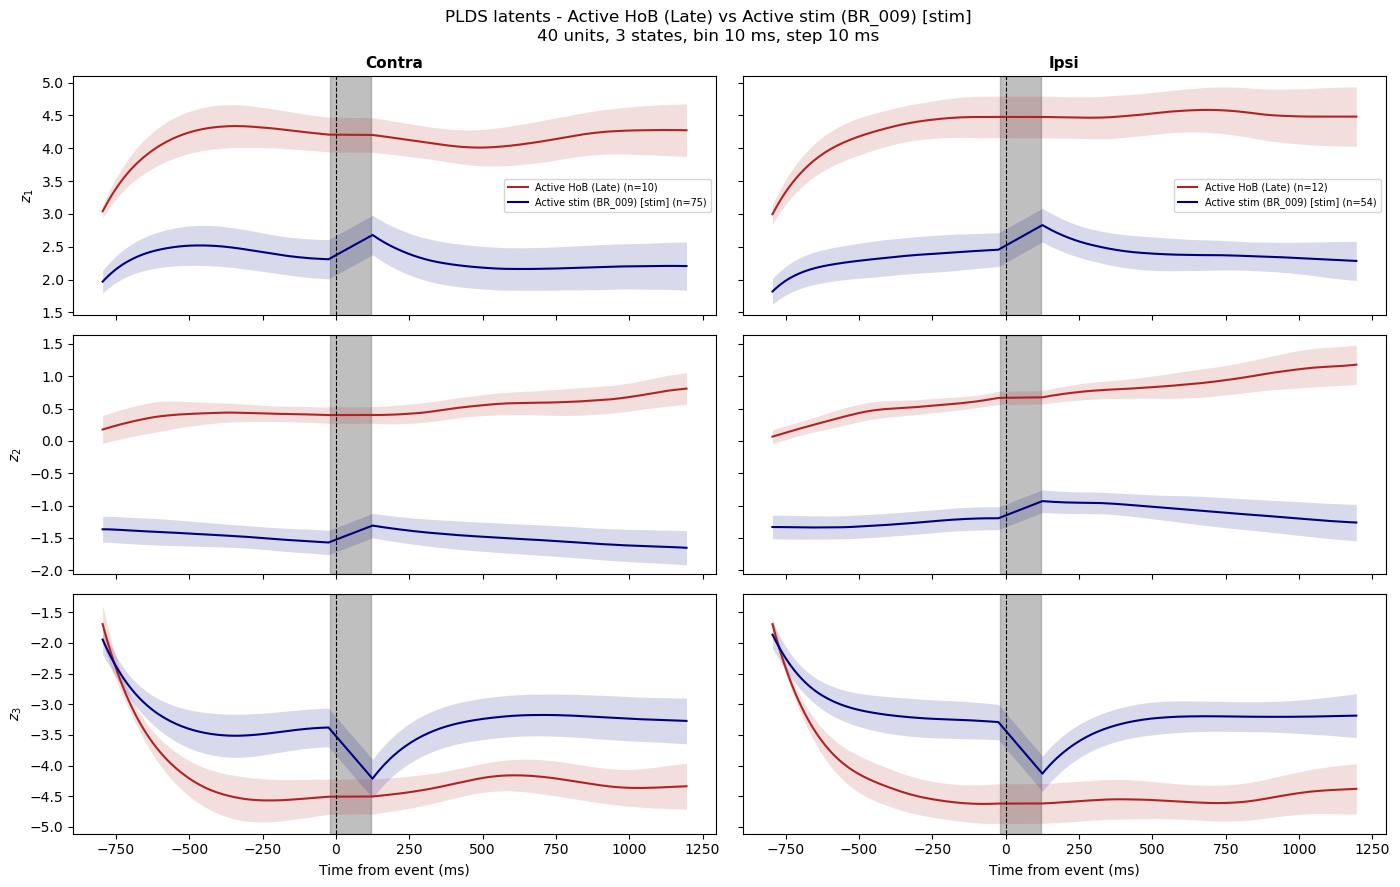

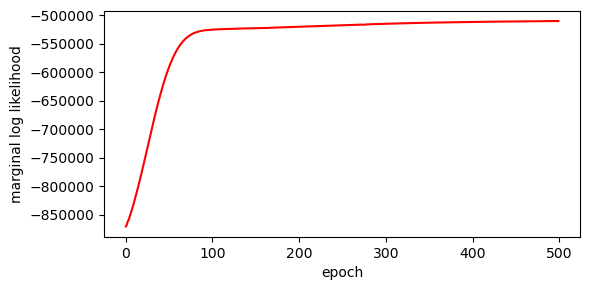

In [29]:
# Rotate to the SVD basis of C so latent dims are ordered by variance explained

params_fit = make_params(C_fit, jnp.exp(log_d_fit), A_fit, B_fit)
posts_fit = vmap(lambda obs, inp: cmgs(params_fit, EKFIntegrals(), obs, inputs=inp))(
    all_obs, all_inp)
predicted = softplus(posts_fit.filtered_means @ C_fit.T + jnp.exp(log_d_fit))
innovations = all_obs - predicted

U, S, Vt = jnp.linalg.svd(C_fit, full_matrices=False)
# Smoothed (forward-backward) means: much less jagged than filtered, but each bin
# also sees later data, so trajectories can bend a bin or two before stim onset
z_all = posts_fit.smoothed_means @ Vt.T

# Columns: direction. Within each panel: control vs stim.
dir_cols = [("Contra", 0), ("Ipsi", 1)]
cond_rows = [(LDS_CONTROL, 0, "firebrick"), (LDS_STIM, 1, "navy")]

z_by_group = {}
for dname, dv in dir_cols:
    for cname, cv, _ in cond_rows:
        m = (cond_lab == cv) & (dir_lab == dv)
        if m.sum() > 0:
            z_by_group[(dname, cname)] = np.asarray(z_all[m])

disp_states = min(4, state_dim)

fig, axs = plt.subplots(disp_states, len(dir_cols),
                        figsize=(7 * len(dir_cols), 3 * disp_states),
                        sharex=True, squeeze=False)

for d in range(disp_states):
    for c, (dname, _) in enumerate(dir_cols):
        ax = axs[d][c]
        for cname, _, color in cond_rows:
            z = z_by_group.get((dname, cname))
            if z is None:
                continue
            m, sd = z[:, :, d].mean(axis=0), z[:, :, d].std(axis=0)
            ax.fill_between(centers_ms, m - sd, m + sd, color=color, alpha=0.15, lw=0)
            ax.plot(centers_ms, m, color=color, lw=1.5, label=f"{cname} (n={z.shape[0]})")
        ax.axvline(0, color="k", lw=0.8, ls="--")
        ax.axvspan(-STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS,
                   color="grey", alpha=0.5, zorder=0)
        if c == 0:
            ax.set_ylabel(rf"$z_{{{d+1}}}$")
        else:
            ax.set_yticklabels([])
        if d == 0:
            ax.set_title(dname, fontsize=11, fontweight="bold")
            ax.legend(fontsize=7)
        if d == disp_states - 1:
            ax.set_xlabel("Time from event (ms)")

    # Lock y across the row so contra and ipsi are directly comparable
    lims = [axs[d][c].get_ylim() for c in range(len(dir_cols))]
    row_lim = (min(l[0] for l in lims), max(l[1] for l in lims))
    for c in range(len(dir_cols)):
        axs[d][c].set_ylim(row_lim)

fig.suptitle(f"PLDS latents - {LDS_CONTROL} vs {LDS_STIM}\n"
             f"{len(lds_units_kept)} units, {state_dim} states, bin {LDS_BIN_MS:.0f} ms, step {LDS_STEP_MS:.0f} ms")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 3))
plt.plot(-np.array(losses), color="r", lw=1.5)
plt.xlabel("epoch"); plt.ylabel("marginal log likelihood")
plt.tight_layout()
plt.show()

In [30]:
# Rotate the latent basis so early axes carry the kinematic-predictive directions
#
# Finds W minimizing ||Z W - Y||^2 + lam||W||^2 with Y the aligned kinematics,
# orthonormalizes W to get the first axes, then completes the basis with the
# neural-variance ordering of what's left. Orthonormal, so it is a rotation of
# the same latent space, not a projection into kinematic space.

KIN_RIDGE = 1e-2
KIN_USE_ACCEL = False

def get_trial_kin(cond_label, dir_key, centers_ms):
    """
    Yaw velocity per trial, interpolated onto the LDS bin centers.

    Args:
        cond_label: cond_cache key.
        dir_key: "contra" or "ipsi".
        centers_ms: LDS bin centers (ms).
    Returns:
        (n_trials, n_bins) velocity, NaN where the window leaves the trace.
    """
    cc = cond_cache[cond_label]
    events = cc["events"][dir_key]
    t_vel, vel = cc["t_vel"], cc["vel"]
    out = np.full((events.size, centers_ms.size), np.nan)
    for i, t0 in enumerate(events):
        tq = t0 + centers_ms / 1000.0
        ok = (tq >= t_vel[0]) & (tq <= t_vel[-1])
        out[i, ok] = np.interp(tq[ok], t_vel, vel)
    return out


# Same iteration order as the block that built all_obs, so trials line up
kin_rows = []
for (cl, dk), counts in blocks.items():
    if counts.shape[0] == 0:
        continue
    kin_rows.append(get_trial_kin(cl, dk, centers_ms))
kin_vel = np.concatenate(kin_rows, axis=0)  # (n_trials, n_bins)
assert kin_vel.shape[0] == num_trials, (kin_vel.shape, num_trials)

# Kinematic targets: velocity, and optionally its derivative
kin_stack = [kin_vel]
if KIN_USE_ACCEL:
    dt_s = np.median(np.diff(centers_ms)) / 1000.0
    kin_stack.append(np.gradient(kin_vel, dt_s, axis=1))
Y_full = np.stack(kin_stack, axis=-1)  # (trials, bins, n_kin)
kin_names = ["yaw vel"] + (["yaw accel"] if KIN_USE_ACCEL else [])

# Flatten to samples, keeping only rows finite in both z and Y
Z_flat = np.asarray(z_all).reshape(-1, z_all.shape[-1])
Y_flat = Y_full.reshape(-1, Y_full.shape[-1])
good = np.isfinite(Z_flat).all(axis=1) & np.isfinite(Y_flat).all(axis=1)
Zg, Yg = Z_flat[good], Y_flat[good]
print(f"{good.sum()}/{good.size} samples usable")

Zc = Zg - Zg.mean(axis=0)
Yc = Yg - Yg.mean(axis=0)
Ys = Yc / Yc.std(axis=0, keepdims=True)  # equal weight per kinematic variable

# Ridge regression from latents to kinematics
K = Zc.shape[1]
W = np.linalg.solve(Zc.T @ Zc + KIN_RIDGE * np.trace(Zc.T @ Zc) / K * np.eye(K),
                    Zc.T @ Ys)  # (K, n_kin)

# Orthonormalize the kinematic directions, then complete the basis
Q_kin, _ = np.linalg.qr(W)
r = Q_kin.shape[1]
R_full = np.linalg.qr(np.hstack([Q_kin, np.eye(K)]))[0][:, :K]
R_kin, R_rest = R_full[:, :r], R_full[:, r:]

# Order the residual axes by neural variance so they are at least reproducible
if R_rest.shape[1] > 1:
    resid = Zc @ R_rest
    _, _, Vt_r = np.linalg.svd(resid - resid.mean(axis=0), full_matrices=False)
    R_rest = R_rest @ Vt_r.T
R_kinrot = np.hstack([R_kin, R_rest])  # (K, K), orthonormal

z_kin = np.asarray(z_all) @ R_kinrot

# Variance in kinematics explained by each rotated axis alone, and cumulatively
def _r2(X, Y):
    X = np.c_[X, np.ones(len(X))]
    beta, *_ = np.linalg.lstsq(X, Y, rcond=None)
    resid = Y - X @ beta
    return 1.0 - (resid ** 2).sum() / ((Y - Y.mean(0)) ** 2).sum()

Zrot = Zc @ R_kinrot
print(f"\nrotation is orthonormal: "
      f"{np.allclose(R_kinrot.T @ R_kinrot, np.eye(K), atol=1e-8)}")
print(f"{'axis':6s} {'R2 alone':>9s} {'R2 cumulative':>14s}  per-variable R2 alone")
for j in range(K):
    alone = _r2(Zrot[:, [j]], Ys)
    cum = _r2(Zrot[:, :j + 1], Ys)
    per = "  ".join(f"{nm}={_r2(Zrot[:, [j]], Ys[:, [i]]):.3f}"
                    for i, nm in enumerate(kin_names))
    print(f"z{j+1:<5d} {alone:9.3f} {cum:14.3f}  {per}")
print(f"\nneural variance kept per axis: "
      f"{np.round(Zrot.var(axis=0) / Zrot.var(axis=0).sum(), 3)}")

28086/28086 samples usable

rotation is orthonormal: True
axis    R2 alone  R2 cumulative  per-variable R2 alone
z1         0.051          0.051  yaw vel=0.051
z2         0.007          0.051  yaw vel=0.007
z3         0.004          0.051  yaw vel=0.004

neural variance kept per axis: [0.145 0.839 0.016]


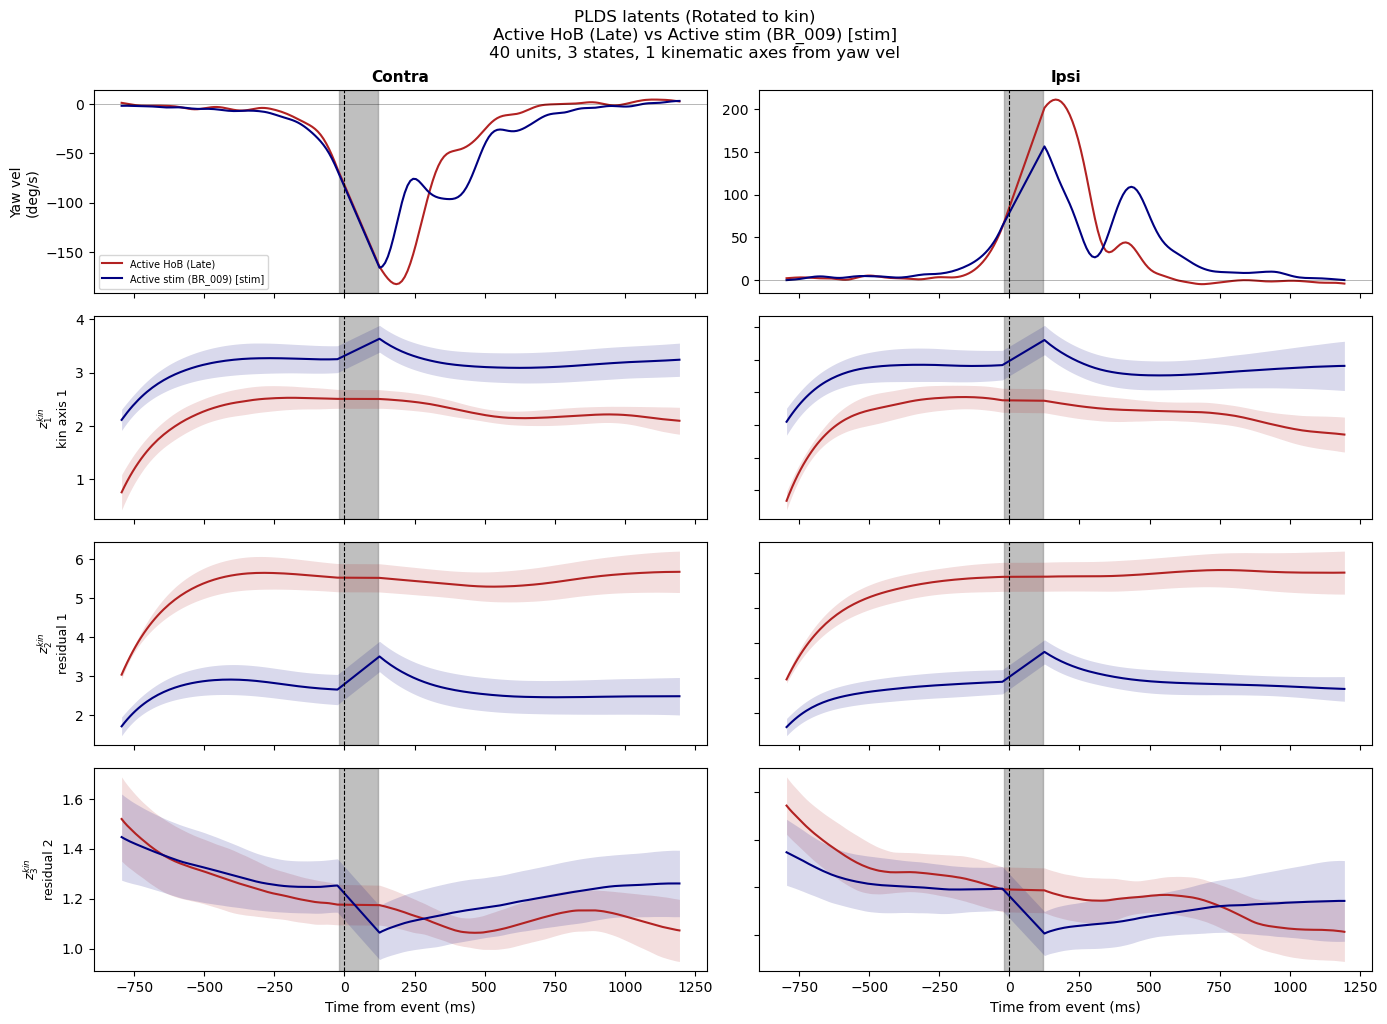

In [31]:
# Same layout as before, on the kinematic-rotated basis, with the mean
# kinematics overlaid so the correspondence is visible

z_by_group = {}
kin_by_group = {}
for dname, dv in dir_cols:
    for cname, cv, _ in cond_rows:
        m = (cond_lab == cv) & (dir_lab == dv)
        if m.sum() > 0:
            z_by_group[(dname, cname)] = z_kin[m]
            kin_by_group[(dname, cname)] = kin_vel[m]

disp_states = state_dim
fig, axs = plt.subplots(disp_states + 1, len(dir_cols),
                        figsize=(7 * len(dir_cols), 2.6 * (disp_states + 1)),
                        sharex=True, squeeze=False)

for c, (dname, _) in enumerate(dir_cols):
    ax = axs[0][c]
    for cname, _, color in cond_rows:
        k = kin_by_group.get((dname, cname))
        if k is None:
            continue
        ax.plot(centers_ms, np.nanmean(k, axis=0), color=color, lw=1.5, label=cname)
    ax.axhline(0, color="k", lw=0.5, alpha=0.4)
    ax.axvline(0, color="k", lw=0.8, ls="--")
    ax.axvspan(-STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS,
                color="grey", alpha=0.5, zorder=0)
    ax.set_title(dname, fontsize=11, fontweight="bold")
    if c == 0:
        ax.set_ylabel("Yaw vel\n(deg/s)")
        ax.legend(fontsize=7)

for d in range(disp_states):
    for c, (dname, _) in enumerate(dir_cols):
        ax = axs[d + 1][c]
        for cname, _, color in cond_rows:
            z = z_by_group.get((dname, cname))
            if z is None:
                continue
            m, sd = z[:, :, d].mean(axis=0), z[:, :, d].std(axis=0)
            ax.fill_between(centers_ms, m - sd, m + sd, color=color, alpha=0.15, lw=0)
            ax.plot(centers_ms, m, color=color, lw=1.5)
        ax.axvline(0, color="k", lw=0.8, ls="--")
        ax.axvspan(-STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS,
                   color="grey", alpha=0.5, zorder=0)
        label = f"kin axis {d+1}" if d < r else f"residual {d - r + 1}"
        if c == 0:
            ax.set_ylabel(rf"$z^{{kin}}_{{{d+1}}}$" + f"\n{label}", fontsize=9)
        else:
            ax.set_yticklabels([])
        if d == disp_states - 1:
            ax.set_xlabel("Time from event (ms)")

    for row in range(disp_states + 1):
        lims = [axs[row][cc].get_ylim() for cc in range(len(dir_cols))]
        rl = (min(l[0] for l in lims), max(l[1] for l in lims))
        # for cc in range(len(dir_cols)):
            # axs[row][cc].set_ylim(rl)

fig.suptitle(f"PLDS latents (Rotated to kin)\n{LDS_CONTROL} vs {LDS_STIM}\n"
             f"{len(lds_units_kept)} units, {state_dim} states, "
             f"{r} kinematic axes from {', '.join(kin_names)}")
plt.tight_layout()
plt.show()

In [48]:
# Align the stim latents to control on the prestim period
#
# Control and stim come from different blocks, so the latent state can already
# differ before anything is delivered. Fits T(z) = z R + t on the prestim bins
# only, taking the stim condition-mean trajectory onto the control one (contra
# and ipsi stacked, so the rotation is pinned by two paths), then applies it to
# every stim trial. Control is left as is. Anything after stim onset is not used
# in the fit, so post-stim divergence is measured from a shared starting point.

ALIGN_MODE = "rigid"  # "shift": translation only; "rigid": rotation + translation
ALIGN_PRE_MS = (-300.0, -STIM_MS_BEFORE)  # starts late to skip the filter warm-up from z0 = 0

z_np = np.asarray(z_all)
n_lat = z_np.shape[-1]
pre_mask = (centers_ms >= ALIGN_PRE_MS[0]) & (centers_ms < ALIGN_PRE_MS[1])
post_mask = centers_ms > STIM_DUR_MS + STIM_TAIL_MS
print(f"prestim fit window: {centers_ms[pre_mask][0]:.0f} to "
      f"{centers_ms[pre_mask][-1]:.0f} ms ({pre_mask.sum()} bins), mode={ALIGN_MODE}")

def group_mean(z, cv, dv):
    """Condition-mean latent trajectory (n_bins, n_lat), None if the group is empty."""
    m = (cond_lab == cv) & (dir_lab == dv)
    return z[m].mean(axis=0) if m.any() else None

# Matched prestim samples, stim -> control, both directions stacked
src, dst = [], []
for _, dv in dir_cols:
    mc, ms = group_mean(z_np, 0, dv), group_mean(z_np, 1, dv)
    if mc is None or ms is None:
        continue
    src.append(ms[pre_mask])
    dst.append(mc[pre_mask])
src, dst = np.concatenate(src), np.concatenate(dst)
mu_src, mu_dst = src.mean(axis=0), dst.mean(axis=0)

if ALIGN_MODE == "shift":
    R_align = np.eye(n_lat)
elif ALIGN_MODE == "rigid":
    # Orthogonal Procrustes, reflection excluded so it is a proper rotation
    U_a, _, Vt_a = np.linalg.svd((src - mu_src).T @ (dst - mu_dst))
    D_a = np.eye(n_lat)
    D_a[-1, -1] = np.sign(np.linalg.det(U_a @ Vt_a))
    R_align = U_a @ D_a @ Vt_a
else:
    raise ValueError(f"ALIGN_MODE must be 'shift' or 'rigid', got {ALIGN_MODE!r}")
t_align = mu_dst - mu_src @ R_align

z_al = z_np.copy()
stim_trials = cond_lab == 1
z_al[stim_trials] = z_np[stim_trials] @ R_align + t_align

# Control-stim distance between condition means, before and after alignment
def cond_gap(z, t_mask):
    """Mean Euclidean distance between control and stim means over t_mask, per direction."""
    out = {}
    for dname, dv in dir_cols:
        mc, ms = group_mean(z, 0, dv), group_mean(z, 1, dv)
        if mc is not None and ms is not None:
            out[dname] = float(np.linalg.norm((mc - ms)[t_mask], axis=-1).mean())
    return out

angles = np.degrees(np.abs(np.angle(np.linalg.eigvals(R_align))))
print(f"rotation angle {angles.max():.1f} deg, shift |t| = {np.linalg.norm(t_align):.3f}")
print(f"{'':8s} {'prestim before':>15s} {'prestim after':>14s} "
      f"{'post before':>12s} {'post after':>11s}")
pre_b, pre_a = cond_gap(z_np, pre_mask), cond_gap(z_al, pre_mask)
post_b, post_a = cond_gap(z_np, post_mask), cond_gap(z_al, post_mask)
for dname in pre_b:
    print(f"{dname:8s} {pre_b[dname]:15.3f} {pre_a[dname]:14.3f} "
          f"{post_b[dname]:12.3f} {post_a[dname]:11.3f}")

prestim fit window: -295 to -25 ms (28 bins), mode=rigid
rotation angle 49.9 deg, shift |t| = 6.585
          prestim before  prestim after  post before  post after
Contra             2.942          0.072        2.996       0.278
Ipsi               3.034          0.068        3.154       0.333


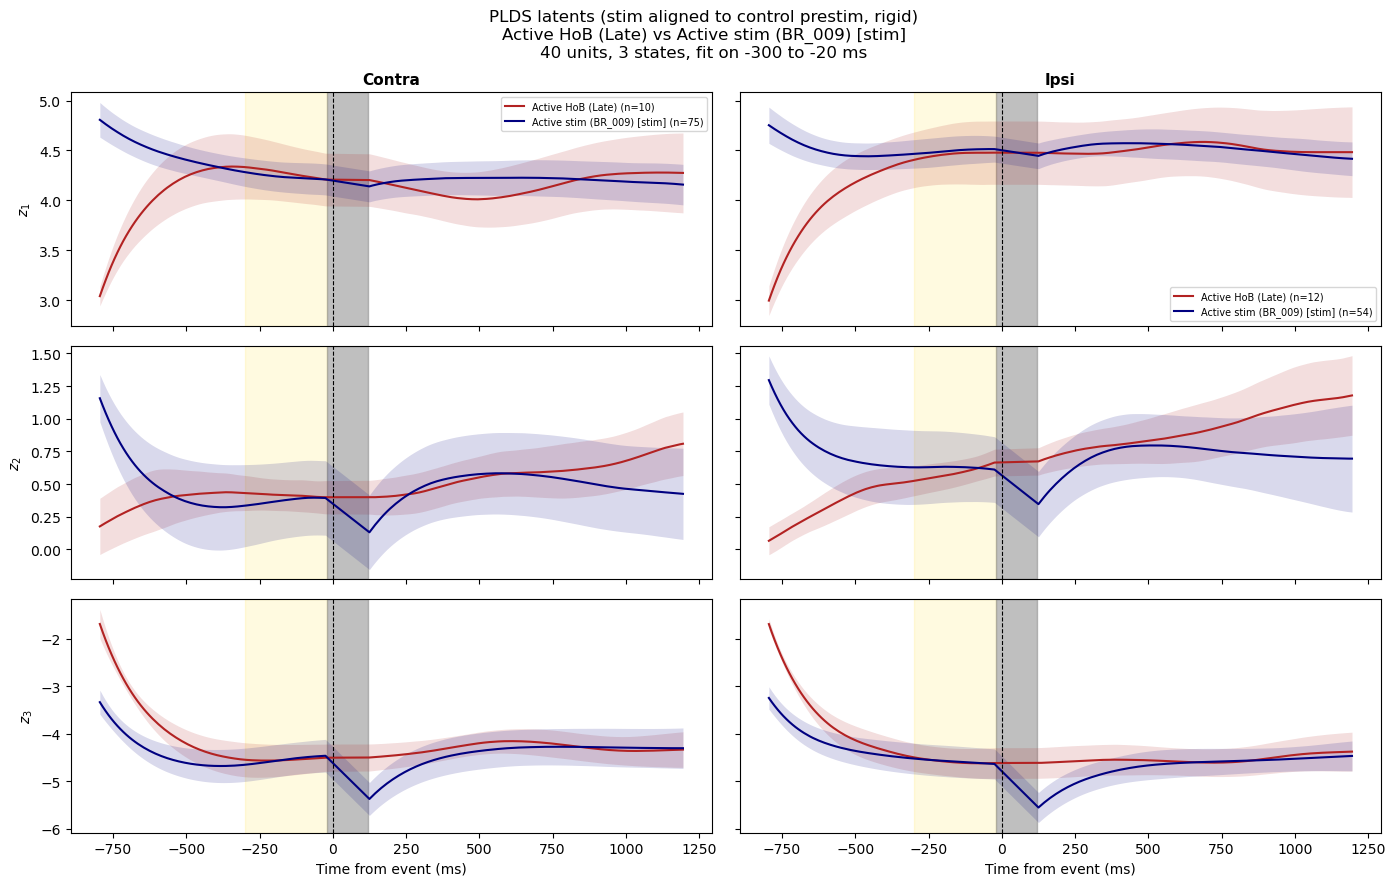

In [49]:
# Same layout as the SVD-basis plot, with stim mapped onto control's prestim.
# Gold band marks the bins the alignment was fit on.

z_by_group = {}
for dname, dv in dir_cols:
    for cname, cv, _ in cond_rows:
        m = (cond_lab == cv) & (dir_lab == dv)
        if m.sum() > 0:
            z_by_group[(dname, cname)] = z_al[m]

disp_states = state_dim
fig, axs = plt.subplots(disp_states, len(dir_cols),
                        figsize=(7 * len(dir_cols), 3 * disp_states),
                        sharex=True, squeeze=False)

for d in range(disp_states):
    for c, (dname, _) in enumerate(dir_cols):
        ax = axs[d][c]
        for cname, _, color in cond_rows:
            z = z_by_group.get((dname, cname))
            if z is None:
                continue
            m, sd = z[:, :, d].mean(axis=0), z[:, :, d].std(axis=0)
            ax.fill_between(centers_ms, m - sd, m + sd, color=color, alpha=0.15, lw=0)
            ax.plot(centers_ms, m, color=color, lw=1.5, label=f"{cname} (n={z.shape[0]})")
        ax.axvspan(*ALIGN_PRE_MS, color="gold", alpha=0.12, zorder=0)
        ax.axvline(0, color="k", lw=0.8, ls="--")
        ax.axvspan(-STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS,
                   color="grey", alpha=0.5, zorder=0)
        if c == 0:
            ax.set_ylabel(rf"$z_{{{d+1}}}$")
        else:
            ax.set_yticklabels([])
        if d == 0:
            ax.set_title(dname, fontsize=11, fontweight="bold")
            ax.legend(fontsize=7)
        if d == disp_states - 1:
            ax.set_xlabel("Time from event (ms)")

    # Lock y across the row so contra and ipsi are directly comparable
    lims = [axs[d][c].get_ylim() for c in range(len(dir_cols))]
    row_lim = (min(l[0] for l in lims), max(l[1] for l in lims))
    for c in range(len(dir_cols)):
        axs[d][c].set_ylim(row_lim)

fig.suptitle(f"PLDS latents (stim aligned to control prestim, {ALIGN_MODE})\n"
             f"{LDS_CONTROL} vs {LDS_STIM}\n"
             f"{len(lds_units_kept)} units, {state_dim} states, fit on "
             f"{ALIGN_PRE_MS[0]:.0f} to {ALIGN_PRE_MS[1]:.0f} ms")
plt.tight_layout()
plt.show()

In [57]:
# Interactive view finder (plotly): drag each panel to rotate it; contra and ipsi
# have their own cameras. When they look right, run the matplotlib portrait below
# with PORTRAIT_VIEW = "plotly" and each panel reuses its own angle. Same aligned latents, window and markers as below,
# except t = 0 is an x here (plotly has no 3D triangle). Hover a line to read its time.

import plotly.graph_objects as go
from plotly.subplots import make_subplots
from matplotlib.colors import to_hex

VF_DIMS = (0, 1, 2)
VF_WIN_MS = (-400.0, 600.0)

vi, vj, vk = VF_DIMS
vf_win = (centers_ms >= VF_WIN_MS[0]) & (centers_ms <= VF_WIN_MS[1])
vf_t = centers_ms[vf_win]
vf_zero = int(np.argmin(np.abs(vf_t)))
vf_dirs = {0: "contra", 1: "ipsi"}
vf_scenes = [f"scene{c + 1 if c else ''}" for c in range(len(dir_cols))]
vf_z = z_al @ R_kinrot

# Blank is forced on every condition, so one window covers both
vf_blanked = np.flatnonzero((vf_t >= -STIM_MS_BEFORE) & (vf_t <= STIM_DUR_MS + STIM_TAIL_MS))

fig_pl = go.FigureWidget(make_subplots(
    rows=1, cols=len(dir_cols), specs=[[{"type": "scene"}] * len(dir_cols)],
    subplot_titles=[d for d, _ in dir_cols], horizontal_spacing=0.02,
))
vf_pts = []

for c, (dname, dv) in enumerate(dir_cols):
    for cname, cv, color in cond_rows:
        m = (cond_lab == cv) & (dir_lab == dv)
        if not m.any():
            continue
        col = to_hex(color)
        P = vf_z[m].mean(axis=0)[vf_win][:, [vi, vj, vk]]
        vf_pts.append(P)

        # Solid where spikes were observed, dotted over the blanked bins
        if vf_blanked.size:
            pieces = [(slice(0, vf_blanked[0] + 1), "solid"),
                      (slice(vf_blanked[0], vf_blanked[-1] + 1), "dot"),
                      (slice(vf_blanked[-1], None), "solid")]
        else:
            pieces = [(slice(None), "solid")]
        for n, (sl, dash) in enumerate(pieces):
            fig_pl.add_trace(go.Scatter3d(
                x=P[sl, 0], y=P[sl, 1], z=P[sl, 2], mode="lines",
                line=dict(color=col, width=5 if dash == "solid" else 3, dash=dash),
                name=f"{cname} (n={int(m.sum())})", legendgroup=cname,
                showlegend=(c == 0 and n == 0),
                hovertext=[f"{cname}: {t:.0f} ms" for t in vf_t[sl]], hoverinfo="text",
            ), row=1, col=c + 1)

        marks = [(0, "circle-open", "start"), (vf_zero, "x", "t = 0"),
                 (len(vf_t) - 1, "square", "end")]
        cc = cond_cache[cname]
        if cc["kind"] == "stim":
            matched, lag = match_events_to_stim(cc["events"][vf_dirs[dv]], cc["stim_onsets_s"],
                                                STIM_MATCH_TOL_MS)
            if matched.any():
                on_ms = -np.median(lag[matched])  # lag +ve: event after onset
                marks.append((int(np.argmin(np.abs(vf_t - on_ms))), "diamond", "stim onset"))
        for idx, sym, lab in marks:
            fig_pl.add_trace(go.Scatter3d(
                x=[P[idx, 0]], y=[P[idx, 1]], z=[P[idx, 2]], mode="markers",
                marker=dict(symbol=sym, size=6, color=col), legendgroup=cname, showlegend=False,
                hovertext=f"{cname}: {lab} ({vf_t[idx]:.0f} ms)", hoverinfo="text",
            ), row=1, col=c + 1)

# Shared ranges and a cube box, the same box the matplotlib figure uses (box aspect 1:1:1)
vf_all = np.vstack(vf_pts)
vf_lo, vf_hi = vf_all.min(axis=0), vf_all.max(axis=0)
vf_pad = 0.05 * (vf_hi - vf_lo)
for key in vf_scenes:
    fig_pl.layout[key].update(
        aspectmode="cube",
        xaxis=dict(title=f"z{vi + 1} (kin)", range=[vf_lo[0] - vf_pad[0], vf_hi[0] + vf_pad[0]]),
        yaxis=dict(title=f"z{vj + 1} (kin)", range=[vf_lo[1] - vf_pad[1], vf_hi[1] + vf_pad[1]]),
        zaxis=dict(title=f"z{vk + 1} (residual)", range=[vf_lo[2] - vf_pad[2], vf_hi[2] + vf_pad[2]]),
    )
fig_pl.update_layout(height=560, margin=dict(l=0, r=0, t=50, b=0),
                     title=f"View finder (stim aligned to control prestim) - {LDS_CONTROL} vs {LDS_STIM}")

def plotly_view(panel=0):
    """(elev, azim) in degrees of one panel's camera (index into dir_cols), or None before any rotation."""
    eye = fig_pl.layout[vf_scenes[panel]].camera.eye
    if eye is None or eye.x is None:
        return None
    x, y, z = eye.x, eye.y, eye.z
    return float(np.degrees(np.arctan2(z, np.hypot(x, y)))), float(np.degrees(np.arctan2(y, x)))

display(fig_pl)

FigureWidget({
    'data': [{'hoverinfo': 'text',
              'hovertext': [Active HoB (Late): -395 ms, Active HoB (Late): -385
                            ms, Active HoB (Late): -375 ms, Active HoB (Late): -365
                            ms, Active HoB (Late): -355 ms, Active HoB (Late): -345
                            ms, Active HoB (Late): -335 ms, Active HoB (Late): -325
                            ms, Active HoB (Late): -315 ms, Active HoB (Late): -305
                            ms, Active HoB (Late): -295 ms, Active HoB (Late): -285
                            ms, Active HoB (Late): -275 ms, Active HoB (Late): -265
                            ms, Active HoB (Late): -255 ms, Active HoB (Late): -245
                            ms, Active HoB (Late): -235 ms, Active HoB (Late): -225
                            ms, Active HoB (Late): -215 ms, Active HoB (Late): -205
                            ms, Active HoB (Late): -195 ms, Active HoB (Late): -185
                            ms

drawing -395 to 595 ms (86 of 186 bins)
Contra view: elev=40.3, azim=-98.7
Ipsi view: elev=19.8, azim=-83.4


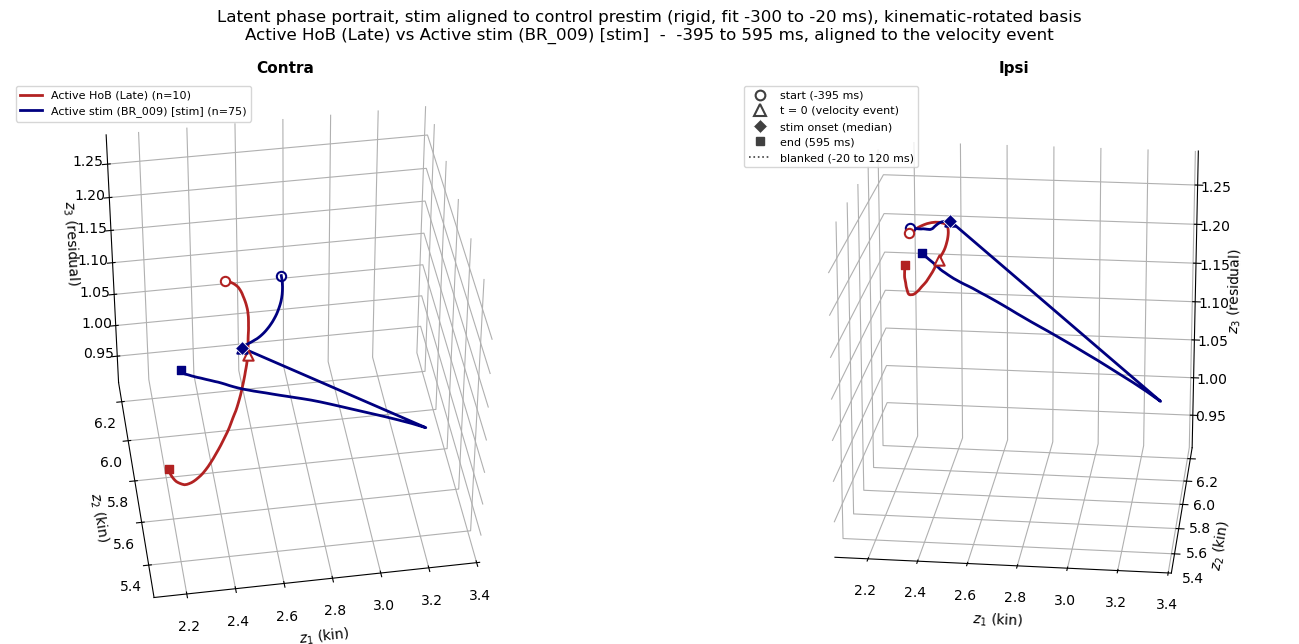

In [58]:
# 3D phase portrait of the prestim-aligned latents, on the kinematic-rotated basis
#
# Uses z_al (stim mapped onto control's prestim), then applies R_kinrot. Both are
# rigid, so rotating after aligning gives the same geometry as aligning in the
# kinematic basis: control is unchanged, and stim starts from control's prestim state.
# z1/z2 are the kinematic-predictive axes; z3 is the first residual axis (ordered by
# neural variance), i.e. state change the kinematics do not account for.
#
# Time 0 is the velocity event. The stim blank is applied to every condition here
# (forced so the grids match), so both are dotted over the same window. The diamond
# sits at the stim condition's median measured onset relative to the event.

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3d projection)
from matplotlib.lines import Line2D

PORTRAIT_DIMS = (0, 1, 2)
PORTRAIT_WIN_MS = (-400.0, 600.0)      # sub-window of LDS_WIN_MS to draw
STIM_LO, STIM_HI = -STIM_MS_BEFORE, STIM_DUR_MS + STIM_TAIL_MS

# View angle per panel: "plotly" reuses the angle each panel was rotated to in the
# view finder above (falls back to PORTRAIT_DEFAULT_VIEW for a panel that has not been
# rotated). Or pass a dict of (elev, azim) in degrees keyed by direction, e.g.
# {"Contra": (10, 45), "Ipsi": (20, -60)}.
PORTRAIT_VIEW = "plotly"
PORTRAIT_DEFAULT_VIEW = (10.0, 45.0)

i, j, k = PORTRAIT_DIMS
win = (centers_ms >= PORTRAIT_WIN_MS[0]) & (centers_ms <= PORTRAIT_WIN_MS[1])
assert win.any(), f"{PORTRAIT_WIN_MS} lies outside LDS_WIN_MS={LDS_WIN_MS}"
t_win = centers_ms[win]
i_zero = int(np.argmin(np.abs(t_win)))  # bin at the event
print(f"drawing {t_win[0]:.0f} to {t_win[-1]:.0f} ms "
      f"({win.sum()} of {centers_ms.size} bins)")

z_al_kin = z_al @ R_kinrot
dir_keys = {0: "contra", 1: "ipsi"}

def stim_onset_ms(cond_label, dir_key):
    """Median stim onset relative to the event (ms), NaN if the condition has no stim."""
    cc = cond_cache[cond_label]
    if cc["kind"] != "stim":
        return np.nan
    matched, lag = match_events_to_stim(cc["events"][dir_key], cc["stim_onsets_s"],
                                        STIM_MATCH_TOL_MS)
    return -float(np.median(lag[matched])) if matched.any() else np.nan  # lag +ve: event after onset

# Blanked bins on the drawn axis, shared by every condition
blanked = np.flatnonzero((t_win >= STIM_LO) & (t_win <= STIM_HI))

fig = plt.figure(figsize=(7.5 * len(dir_cols), 6.5))
axes3d = []

for c, (dname, dv) in enumerate(dir_cols):
    ax = fig.add_subplot(1, len(dir_cols), c + 1, projection="3d")
    axes3d.append(ax)

    for cname, cv, color in cond_rows:
        m = (cond_lab == cv) & (dir_lab == dv)
        if m.sum() == 0:
            continue
        P = z_al_kin[m].mean(axis=0)[win][:, [i, j, k]].T

        if blanked.size:
            lo, hi = blanked[0], blanked[-1]
            ax.plot(*P[:, :lo + 1], color=color, lw=1.8, zorder=3)
            ax.plot(*P[:, lo:hi + 1], color=color, lw=1.2, ls=":", zorder=3)
            ax.plot(*P[:, hi:], color=color, lw=2.4, zorder=4,
                    label=f"{cname} (n={int(m.sum())})")
        else:
            ax.plot(*P, color=color, lw=2.0, zorder=3,
                    label=f"{cname} (n={int(m.sum())})")

        ax.scatter(*P[:, 0], marker="o", s=45, facecolor="white",
                   edgecolor=color, linewidth=1.5, zorder=6)                 # window start
        ax.scatter(*P[:, i_zero], marker="^", s=55, facecolor="white",
                   edgecolor=color, linewidth=1.5, zorder=7)                 # event, t = 0
        on_ms = stim_onset_ms(cname, dir_keys[dv])
        if np.isfinite(on_ms):
            i_on = int(np.argmin(np.abs(t_win - on_ms)))
            ax.scatter(*P[:, i_on], marker="D", s=50, color=color,
                       edgecolor="white", linewidth=0.6, zorder=8)           # stim onset
        ax.scatter(*P[:, -1], marker="s", s=38, color=color, zorder=6)       # window end

    ax.set_xlabel(rf"$z_{{{i+1}}}$ (kin)"); ax.set_ylabel(rf"$z_{{{j+1}}}$ (kin)")
    ax.set_zlabel(rf"$z_{{{k+1}}}$ (residual)")
    ax.set_title(dname, fontsize=11, fontweight="bold")
    ax.set_box_aspect((1, 1, 1))
    for pane in (ax.xaxis, ax.yaxis, ax.zaxis):
        pane.set_pane_color((1, 1, 1, 0))
    if c == 0:
        ax.legend(fontsize=8, loc="upper left")
    else:
        # Marker key, in neutral ink so it reads as shape-only
        ink = "0.25"
        ax.legend(handles=[
            Line2D([], [], ls="none", marker="o", ms=7, mfc="white", mec=ink, mew=1.5,
                   label=f"start ({t_win[0]:.0f} ms)"),
            Line2D([], [], ls="none", marker="^", ms=8, mfc="white", mec=ink, mew=1.5,
                   label="t = 0 (velocity event)"),
            Line2D([], [], ls="none", marker="D", ms=7, color=ink, mec="white", mew=0.6,
                   label="stim onset (median)"),
            Line2D([], [], ls="none", marker="s", ms=6, color=ink,
                   label=f"end ({t_win[-1]:.0f} ms)"),
            Line2D([], [], color=ink, lw=1.2, ls=":",
                   label=f"blanked ({STIM_LO:.0f} to {STIM_HI:.0f} ms)"),
        ], fontsize=8, loc="upper left")

# Lock all three axes across the panels so contra and ipsi are directly comparable,
# the same way the time-series rows share a y limit
for d, setlim in ((i, "set_xlim"), (j, "set_ylim"), (k, "set_zlim")):
    lims = [getattr(a, setlim.replace("set_", "get_"))() for a in axes3d]
    lo, hi = min(l[0] for l in lims), max(l[1] for l in lims)
    for a in axes3d:
        getattr(a, setlim)(lo, hi)

for c, ((dname, _), a) in enumerate(zip(dir_cols, axes3d)):
    if PORTRAIT_VIEW == "plotly":
        view = globals().get("plotly_view", lambda panel: None)(c)
        if view is None:
            print(f"{dname}: view finder not run or not rotated yet; using default view")
            view = PORTRAIT_DEFAULT_VIEW
    else:
        view = tuple(PORTRAIT_VIEW.get(dname, PORTRAIT_DEFAULT_VIEW))
    a.view_init(elev=view[0], azim=view[1])
    print(f"{dname} view: elev={view[0]:.1f}, azim={view[1]:.1f}")

fig.suptitle(f"Latent phase portrait, stim aligned to control prestim ({ALIGN_MODE}, "
             f"fit {ALIGN_PRE_MS[0]:.0f} to {ALIGN_PRE_MS[1]:.0f} ms), kinematic-rotated basis\n"
             f"{LDS_CONTROL} vs {LDS_STIM}  -  {t_win[0]:.0f} to {t_win[-1]:.0f} ms, "
             f"aligned to the velocity event")
plt.tight_layout()
plt.show()